This notebook is generating all the plots for the publication and generating a combined dataset

### Imports

In [1]:
### Calculation and Interpolation
import numpy as np
from scipy import stats
from scipy.signal import find_peaks
from scipy.stats import circmean, circstd
from scipy.optimize import minimize_scalar
from scipy.interpolate import RegularGridInterpolator,interp1d,CubicSpline
from skimage.morphology import disk
from astropy.convolution import convolve

### Self defined Y-Junction class
import sys
sys.path.append("../extract-topo/") 
from YjunctionClass import Yjunction

### Netcdf files
import xarray as xr

### Tables and Shapefiles
import pandas as pd
import geopandas as gpd
from shapely import Point, Polygon,LineString, MultiPoint, MultiLineString

### Rasterio (Raster data)
import rasterio
from rasterio.plot import show
from rasterio.enums import Resampling
from rasterio.windows import Window,from_bounds
from rasterio.warp import reproject, Resampling
from rasterio.transform import xy, from_origin

### Plotting
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap,LinearSegmentedColormap
from matplotlib.mathtext import _mathtext as mathtext
from matplotlib.offsetbox import TextArea, HPacker, VPacker, AnchoredOffsetbox
import matplotlib.patheffects as pe
                                 
lw  = 0.75                                              # linewidths
fs  = 7                                                # fontsize
dpi = 300                                              # resolution, dots (pixels) per inch (can up to 600 if needed)
plt.plot(np.nan)                                       # don't know why needed but makes the below take effect for me 
plt.close()
plt.rcParams['figure.facecolor'] = 'white'              # make the plot backgrounds transparent (useful for background axes drafting and panel labels
plt.rcParams['figure.dpi'] = dpi                       # make plots have standard resolution
plt.rcParams['font.sans-serif'] = 'Arial'              # font for plots (use Arial, Helvetica, or Times New Roman)
plt.rcParams['font.size'] = fs                         # fontsize unless otherwise stated
plt.rcParams['mathtext.fontset'] = 'custom'            # makes LaTeX typeset in the font above
plt.rcParams['axes.linewidth'] = lw                    # axes linewidths (too thick by default)
plt.rcParams['xtick.direction'] = 'in'                 # ticks inward gives more space
plt.rcParams['ytick.direction'] = 'in'                 # as above 
plt.rcParams['xtick.major.size'] = 4*lw                # tick length (4x thickness is nice)
plt.rcParams['ytick.major.size'] = 4*lw                # as above
plt.rcParams['xtick.major.width'] = lw                 # tick linewidths (too thick by default)
plt.rcParams['ytick.major.width'] = lw                 # as above
plt.rcParams['figure.titlesize'] = fs+1                # rarely used but plot title fontsize...
plt.rcParams['figure.titleweight'] = 'bold'            # ... and thickness
plt.rcParams['legend.frameon'] = False                 # no box around legend
plt.rcParams['legend.handlelength'] = lw*2             # length of lines in the legend
plt.rcParams['lines.linewidth'] = lw                   # line width
plt.rcParams['lines.markersize'] = lw*2                # marker size
plt.rcParams['grid.linewidth'] = lw                    # grid line width
plt.rcParams['axes.xmargin'] = 0                       # supress pad of axes limits around data
plt.rcParams['axes.ymargin'] = 0                       # as above
plt.rcParams['image.origin'] = 'lower'                 # make imshow put origin in bottom left not top left
plt.rcParams['hatch.linewidth'] = 0.3                  # thinner hatches
mathtext.FontConstantsBase.sup1 = 0.5               

### Functions

In [2]:
# from Foroutan et al., 2017
def ut(ut0,fr,fm=1):
    return ut0*fm*fr
    
def ut0(D,rho_p=2650,rho_a=1.2,g=9.81,AN=0.0123,T=1.65e-4):
    return np.sqrt(AN*(((rho_p*g*D)/(rho_a))+((T)/(rho_a*D))))

def fr(A_v,lam_s,sigma_v=1.45,m_v=0.16,beta_v=202,sigma_s=1.0,m_s=0.5,beta_s=90):
    lam_v = -0.35*np.log(1-A_v)
    return np.sqrt((1-sigma_v*m_v*lam_v)*(1+beta_v*m_v*lam_v)*(1-sigma_s*m_s*(lam_s/(1-A_v)))*(1+beta_s*m_s*(lam_s/(1-A_v))))

def Av_from_ut(ut,D,rho_p=2650,rho_a=1.2,g=9.81,AN=0.0123,T=1.65e-4,sigma_v=1.45,m_v=0.16,beta_v=202):
    ut0_val = np.sqrt(AN * (((rho_p*g*D)/(rho_a)) + (T)/(rho_a*D)))
    fr_val = ut / ut0_val
    a = sigma_v * m_v
    b = beta_v * m_v
    A = a * b
    B = -(b - a)
    C = fr_val**2 - 1
    disc = B**2 - 4*A*C
    disc = np.where(disc < 0, np.nan, disc)
    lam1 = (-B + np.sqrt(disc)) / (2*A)
    lam2 = (-B - np.sqrt(disc)) / (2*A)
    lam = np.where(
    (lam1 > 0) & (lam2 > 0),
    np.minimum(lam1, lam2),   # pick smaller positive
    np.where(lam1 > 0, lam1, lam2))
    Av = 1 - np.exp(-lam / 0.35)
    # had to fix
    Av[fr_val<1] = np.nan
    Av[fr_val==1] = 0
    return Av

### Reusing functions from the crest line extraction workflow to generate data for example cell
def limit_neg_pi_less_0(ang):
    if ang>=0:
        ang = ang - np.pi
    if ang==0:
        ang = -np.pi
    return ang
    
def ang_new(x_left,x_right,y_left,y_right):
    xs = np.array([x_left,x_right])
    ys = np.array([y_left,y_right])
    
    if not len(np.unique(xs))<2:
        if not len(np.unique(ys))<2:
            ang = limit_neg_pi_less_0(np.arctan((ys[1]-ys[0])/(xs[1]-xs[0])))
        else:
            ang=-np.pi
    else:
        ang = -np.pi/2
        
    return ang
    
def get_ang_from_pnts(ppnt, npnt):
    x_left = ppnt.x
    x_right = npnt.x
    y_left = ppnt.y
    y_right = npnt.y
    ang = float(ang_new(x_left,x_right,y_left,y_right))
    return ang


def samp_line(line, step=30, offset=15, poff=.001, noff=.001):
    spnts = line.interpolate(np.arange(offset,line.length-offset,step))

    if ((len(spnts)==0) or (len(spnts)==1)):
        spnts = line.interpolate([line.length/2])
        ppnts = line.interpolate([line.length/2-poff])
        npnts = line.interpolate([line.length/2+noff])
    else:
        ppnts = line.interpolate(np.arange(offset-poff,line.length-offset,step))
        npnts = line.interpolate(np.arange(offset+noff,line.length-offset,step))
        
        if not (len(ppnts) == len(spnts) == len(npnts)):
            if (len(ppnts) > len(npnts)):
                ppnts = ppnts[:-abs(len(ppnts) - len(npnts))]
            elif (len(ppnts) < len(npnts)): #should never happen
                npnts = npnts[:-abs(len(ppnts) - len(npnts))]
    
            # can just check ppnts (same as npnts in len)
            if (len(ppnts) > len(spnts)):
                ppnts = ppnts[:-abs(len(ppnts) - len(spnts))]
                npnts = npnts[:-abs(len(npnts) - len(spnts))]
            elif (len(ppnts) < len(spnts)):
                spnts = spnts[:-abs(len(ppnts) - len(spnts))]
            
            # if above results in less than two sample points (like above)
            if (len(spnts)<2):
                spnts = line.interpolate([line.length/2])
                ppnts = line.interpolate([line.length/2-poff])
                npnts = line.interpolate([line.length/2+noff])

    df = pd.DataFrame({"ppnts":ppnts,"npnts":npnts})
    df["angs_3577"] = df.apply(lambda x: get_ang_from_pnts(x.ppnts,x.npnts), axis=1)
    df["centroids"] = spnts
    return df.drop(["ppnts","npnts"],axis=1)

def find_centroid_idx(line, pnt):
    "find the index of the centroid across the line"
    return np.argmin(abs(np.sum(np.array(list(line.coords))-(pnt.x, pnt.y),axis=1)))

def get_peak_troughs(trans_heights, centroid_idx):
    
    # centroid_idx = len(trans_heights)//2
    peaks_idx = find_peaks(trans_heights)[0]
    troughs_idx = find_peaks(-trans_heights)[0]
    if len(peaks_idx) == 0:
        return -1, -1, -1
    try:
        centroid_is_peak = ((trans_heights[centroid_idx-1] < trans_heights[centroid_idx]) and (trans_heights[centroid_idx] > trans_heights[centroid_idx+1]))
    except IndexError:
        return -1, -1, -1
        
    higher_idx_is_upslope = trans_heights[centroid_idx+1] > trans_heights[centroid_idx]
    lower_idx_is_upslope = trans_heights[centroid_idx-1] > trans_heights[centroid_idx]
    
    # if trough for some reason
    if (higher_idx_is_upslope and lower_idx_is_upslope):
        return -1, -1, -1

    try:
        if centroid_is_peak:
            peak = centroid_idx 
        elif higher_idx_is_upslope:
            peak = peaks_idx[peaks_idx>centroid_idx][0]
        else:
            peak = peaks_idx[peaks_idx<centroid_idx][-1]
    except IndexError:
        return -1, -1, -1

    try:
        lower_trough = troughs_idx[troughs_idx<peak][-1]
    except IndexError:
        lower_trough = 0
    
    try:
        upper_trough = troughs_idx[troughs_idx>peak][0]
    except IndexError:
        upper_trough = len(trans_heights)-1

    return lower_trough, peak, upper_trough

def isolate_dune(x_trans, trans_heights, lower_trough_idx, peak_idx, upper_trough_idx, threshold):
    if np.isnan(threshold):
        return np.nan, np.nan, np.nan, np.nan

    mask = trans_heights[lower_trough_idx:upper_trough_idx+1]>=(threshold)
    isolated_height = trans_heights[lower_trough_idx:upper_trough_idx+1][mask]
    isolated_x = x_trans[lower_trough_idx:upper_trough_idx+1][mask]

    new_peak_idx = np.argwhere(isolated_height == trans_heights[peak_idx])[0,0]

    upper_min = isolated_height[new_peak_idx:].min()
    lower_min = isolated_height[:new_peak_idx+1].min()
    
    if upper_min>=lower_min:
        isolated_x = isolated_x[isolated_height>=upper_min]
        isolated_height = isolated_height[isolated_height>=upper_min]
    else:
        isolated_x = isolated_x[isolated_height>=lower_min]
        isolated_height = isolated_height[isolated_height>=lower_min]
    
    final_peak_idx = np.argwhere(isolated_height == trans_heights[peak_idx])[0,0]
    
    return isolated_x, isolated_height, final_peak_idx

def get_chunked_line(line,step):
    linel = line.length
    pnts = line.interpolate(np.arange(linel%step/2,linel-linel%step/2+step,step))
    pnts = [(pnt.x,pnt.y) for pnt in pnts]
    if len(pnts)==1:
        return MultiLineString([line])
    line_sects = []
    for i in range(len(pnts)):
        try:
            line_sects.append(LineString([[pnts[i][0],pnts[i][1]],[pnts[i+1][0],pnts[i+1][1]]]))
        except IndexError:
            continue
    return MultiLineString(line_sects)

def ang_sect(line):
    xs = np.asarray(line.xy[0])
    ys = np.asarray(line.xy[1])

    if len(np.unique(xs))>1:
        if len(xs)>2:
            linea0 = np.arctan(np.polyfit(xs,ys,deg=1)[0])
        else:
            linea0 = np.arctan((ys[1]-ys[0])/(xs[1]-xs[0]))
    else:
        linea0 = np.pi/2

    if len(np.unique(ys))>1:
        if len(ys)>2:
            linea1 = np.arctan(np.polyfit(ys,-xs,deg=1)[0])
        else:
            linea1 = np.arctan((xs[0]-xs[1])/(ys[1]-ys[0]))
    else:
        linea1 = np.pi/2

    return linea0,linea1

def ang_group(linea0,linea1):
    if circstd(linea1)>circstd(linea0):
        crestangleavgs = np.angle(np.sum(np.exp(1j*linea0)))
        crestanglestds = circstd(linea0)
    else:
        crestangleavgs = np.angle(np.sum(np.exp(1j*(linea1+np.pi/2))))
        crestanglestds = circstd(linea1)

    return crestangleavgs, crestanglestds

def get_bisectors_for_line_test(pnt,line_series,radius=[0.51]):
    if len(line_series)<3:
        return np.ones(10)*np.nan
    yj = Yjunction(pnt,line_series)
    yj.get_radius_intersects(radius)
    yj.get_angle_intersects()
    yj.get_angle_between_points()
    # print(yj.get_angle_between_points())
    yj.get_bisectors_between_points()
    junction_params = yj.get_junction_opening_and_direction()
    junction_params = list(junction_params.values())[0]

    # output dictionary init
    outdict = {}
    outdict["minrad_oang"] = np.nan
    outdict["minrad_bdir"] = np.nan
    fillmax = False
    for i,rad in enumerate(radius):
        try:
            outdict[str(rad)+"_oang"] = junction_params[str(rad)]["opening_angle"]
            outdict[str(rad)+"_bdir"] = junction_params[str(rad)]["bisector_direction"]
        except KeyError:
            if i == 0:
                outdict["minrad_oang"] = list(junction_params.values())[0]["opening_angle"]
                outdict["minrad_bdir"] = list(junction_params.values())[0]["bisector_direction"]
            elif len(yj.radii)>1:
                fillmax = True
            outdict[str(rad)+"_oang"] = np.nan
            outdict[str(rad)+"_bdir"] = np.nan
            
    if fillmax:
        outdict["maxrad_oang"] = list(junction_params.values())[-1]["opening_angle"]
        outdict["maxrad_bdir"] = list(junction_params.values())[-1]["bisector_direction"]
    else:
        outdict["maxrad_oang"] = np.nan
        outdict["maxrad_bdir"] = np.nan

    return outdict

#### Andrew's code to extrapolate ####
def extrapolate_angles(theta, boundary="wrap"):
    thetat = np.empty(theta.shape)*np.nan
    for i in np.arange(8,-1,-1):
        kernel = disk(i).astype(float)
        kernel/= np.sum(kernel)
        temp = np.arctan2(convolve(np.sin(theta),kernel,boundary=boundary),convolve(np.cos(theta),kernel,boundary=boundary))
        thetat[~np.isnan(temp)] = temp[~np.isnan(temp)]
    
    temp = np.min((((np.argwhere(~np.isnan(thetat))[:,0][None,:]-np.argwhere(~np.isnan(theta))[:,0][:,None])**2+(np.argwhere(~np.isnan(thetat))[:,1][None,:]-np.argwhere(~np.isnan(theta))[:,1][:,None])**2)**0.5),0).astype(int)
    tempsmooth = np.empty((np.max(temp)+1,*thetat.shape))*np.nan
    for i in range(np.max(temp)+1):
        kernel = disk(i).astype(float)
        kernel/= np.sum(kernel)
        tempsmooth[i] = np.arctan2(convolve(np.sin(thetat),kernel,boundary=boundary),convolve(np.cos(thetat),kernel,boundary=boundary))
    thetasmooth = np.empty(theta.shape)*np.nan
    tempinds = np.hstack((temp[:,None],np.argwhere(~np.isnan(thetat)))).T
    thetasmooth[~np.isnan(thetat)] = tempsmooth[tempinds[0],tempinds[1],tempinds[2]]
    
    return thetasmooth

# setup for special "colorbar"
def round_colorbar(ax, cmap):
    """function to generate a patch that mimics a circular colorbar"""
    re, im = np.mgrid[-1:1:1000j, -1:1:1000j]
    angle = np.angle(re + 1j*im)
    
    # Create a mask for the circle
    radius = 0.5
    circle_mask = re**2 + im**2 <= radius**2
    
    radius_inner = .25
    circle_mask_inner = re**2 + im**2 <= radius_inner**2
    
    # Apply the mask to the angle data
    angle = np.where(circle_mask, angle, np.nan)
    angle = np.where(~circle_mask_inner, angle, np.nan)
    
    ax.pcolormesh(re, im, angle, cmap=cmap, zorder=2,rasterized=True)
    ax.axis('scaled')
    circle3 = plt.Circle((0, 0), radius, edgecolor='black', fill=False, zorder=3)
    circle4 = plt.Circle((0, 0), radius_inner, edgecolor='black', fill=False, zorder=3)
    ax.text(0, 0.6, 'N', color='black', ha='center', va='center_baseline', fontsize=8)
    ax.text(0, -0.6, 'S', color='black', ha='center', va='center_baseline', fontsize=8)
    ax.text(0.575, 0, 'E', color='black', ha='center', va='center_baseline', fontsize=8)
    ax.text(-0.625, 0, 'W', color='black', ha='center', va='center_baseline', fontsize=8)
    # ax.hlines(0, radius_inner, 0.58, color='black', lw=2, zorder=1)
    # ax.vlines(0, radius_inner, 0.58, color='black', lw=2, zorder=1)
    # ax.hlines(0, -radius_inner, -radius -0.08, color='black', lw=2, zorder=1)
    # ax.vlines(0, -radius_inner, -radius -0.08, color='black', lw=2, zorder=1)
    ax.add_patch(circle3)
    ax.add_patch(circle4)

def AUS_back(ax):
    AUS_shp.plot(ax=ax, facecolor='dimgray', edgecolor='none', zorder=0)
    AUS_shp.plot(ax=ax, facecolor='none', edgecolor='black', lw=0.5, zorder=10)

# setup for special "colorbar"
def round_colorbar_small(ax, cmap):
    """function to generate a patch that mimics a circular colorbar"""
    re, im = np.mgrid[-1:1:1000j, -1:1:1000j]
    angle = np.angle(re + 1j*im)
    
    # Create a mask for the circle
    radius = 0.5
    circle_mask = re**2 + im**2 <= radius**2
    
    radius_inner = .25
    circle_mask_inner = re**2 + im**2 <= radius_inner**2
    
    # Apply the mask to the angle data
    angle = np.where(circle_mask, angle, np.nan)
    angle = np.where(~circle_mask_inner, angle, np.nan)
    
    ax.pcolormesh(re, im, angle, cmap=cmap, zorder=2,rasterized=True)
    ax.axis('scaled')
    circle3 = plt.Circle((0, 0), radius, edgecolor='black', fill=False, zorder=3)
    circle4 = plt.Circle((0, 0), radius_inner, edgecolor='black', fill=False, zorder=3)
    ax.text(0, 0.7, 'N', color='black', ha='center', va='center_baseline', fontsize=8)
    ax.text(0, -0.7, 'S', color='black', ha='center', va='center_baseline', fontsize=8)
    ax.text(0.675, 0, 'E', color='black', ha='center', va='center_baseline', fontsize=8)
    ax.text(-0.75, 0, 'W', color='black', ha='center', va='center_baseline', fontsize=8)
    # ax.hlines(0, radius_inner, 0.58, color='black', lw=2, zorder=1)
    # ax.vlines(0, radius_inner, 0.58, color='black', lw=2, zorder=1)
    # ax.hlines(0, -radius_inner, -radius -0.08, color='black', lw=2, zorder=1)
    # ax.vlines(0, -radius_inner, -radius -0.08, color='black', lw=2, zorder=1)
    ax.add_patch(circle3)
    ax.add_patch(circle4)

def bin_veg_ut(ut,veg,n_points=2,bins=np.arange(0, 101, 3)):
    dftemp = pd.Series(veg).to_frame("veg")
    dftemp["elon"] = pd.Series(ut)
    dftemp = dftemp.dropna().sort_values("veg")
    dftemp["veg_bin"] = pd.cut(dftemp["veg"], bins, include_lowest=True) # to ensure 0 values arwe counted
    counts = dftemp.groupby("veg_bin", observed=False).size()

    grouped = dftemp.groupby("veg_bin",observed=False).agg({"veg": "median","elon": "median"}).dropna()
    grouped["elon_q25"] = dftemp.groupby("veg_bin",observed=False).elon.quantile(0.25)
    grouped["elon_q75"] = dftemp.groupby("veg_bin",observed=False).elon.quantile(0.75)
    grouped["veg_center"] = grouped.index.map(lambda b: b.mid)
    grouped["count"] = counts
    grouped = grouped[grouped["count"] > n_points]
    # return dftemp, counts
    return grouped.veg_center,grouped.elon,grouped.elon_q25,grouped.elon_q75

def interp_cell(v, u0, ut):
    if np.isnan(u0) or u0 < ut[0] or u0 > ut[-1]:
        return np.nan
    return np.interp(u0, ut, v)

def fit_stats(g):
    res = stats.linregress(g.tot_cov, g.delta_ut)
    rho, _ = stats.spearmanr(g.tot_cov, g.delta_ut)
    return res, rho

### Definitions

In [3]:
s2y = 365*24*60*60

# flux constants
z            = 10
z0           = 1e-3
kappa        = 0.41
beta         = 6/2 # to "match" Courrech du Pont et al. 2024 with my aspect definition
g            = 9.81
rho_s        = 2650
rho_f        = 1.2
fluxconstant = 5/0.6
fluxk        = fluxconstant/g*rho_f/rho_s

utk = float(6.5*kappa/np.log(z/z0)) # they report the value of 6.5 m/s at 10 m height from Kalma paper

### Shapefile of Australia ###
AUS_shp = gpd.read_file("../Data/Crestlines/Australia_final_shape_4326.shp")

### Combine datasets and calculations for continent wide plots

In [4]:
### Main dataset ###
ds = xr.open_dataset("../get-ERA5-winds/era5-land_1950_2025_ut_opt_dynamic_dm.nc")

### Sensitivity of the elongationmode for a change in threshold speed and for a change in latitude. Using a fixed aspect ratio (median of all slopes across dune whorl).
dsfix = xr.load_dataset("../get-ERA5-winds/era5-land_1950_2025_ut_opt_fixed_dm.nc") # this is the same dataset as the dynamic one but everything calculated for a fixed aspect ratio for sensitivity.
dsfix["daedphi_fix"] = (((dsfix.ae.diff("latitude")+np.pi)%(2*np.pi)-np.pi)/dsfix.latitude.diff("latitude")).reindex(latitude=dsfix.latitude)
dsfix['daedphi_fix'].attrs['long_name'] = 'Derivative of the elongation mode $\\partial\\alpha_E$/$\\partial\\phi$ for fixed aspect ratio.'
dsfix['daedphi_fix'].attrs['units'] = 'rad/DD'
dsfix['daedphi_fix'].attrs['description'] = 'Derivative of the elongation mode $\\alpha_E$ with respect to $\\phi$ for fixed aspect ratio (median of dm).'
dsfix["daedut_fix"] = (((dsfix.ae.diff("ut")+np.pi)%(2*np.pi)-np.pi)/dsfix.ut.diff("ut")).reindex(ut=dsfix.ut)
dsfix['daedut_fix'].attrs['long_name'] = 'Derivative of the elongation mode $\\partial\\alpha_E$/$\\partial u_{\\ast,th}$  for fixed aspect ratio.'
dsfix['daedut_fix'].attrs['units'] = 'rad/ms$^{-1}$'
dsfix['daedut_fix'].attrs['description'] = 'Derivative of the elongation mode $\\alpha_E$ with respect to $u_{\\ast,th}$ for fixed aspect ratio (median of dm)..'
dsfix['daedut_fix'].attrs['units'] = 'rad/ms$^{-1}$'
dsfix["daedut_kalma_fix"] = dsfix.daedut_fix.interp(ut=utk)
dsfix['daedut_kalma_fix'].attrs['long_name'] = '$\\partial\\alpha_E$/$\\partial\\phi$ evaluated at $u_{\\ast,th_{kalma}}$ for fixed aspect ratio.'
dsfix['daedut_kalma_fix'].attrs['units'] = 'rad/ms$^{-1}$'
dsfix['daedut_kalma_fix'].attrs['description'] = '$\\partial\\alpha_E$/$\\partial\\phi$ evaluated at $u_{\\ast,th_{kalma}}$ for fixed aspect ratio (median of dm).'
dsfix["daedphi_kalma_fix"] = dsfix.daedphi_fix.interp(ut=utk)
dsfix['daedphi_kalma_fix'].attrs['long_name'] = '$\\partial\\alpha_E$/$\\partial\\phi$ evaluated at $u_{\\ast,th_{kalma}}$ for fixed aspect ratio.'
dsfix['daedphi_kalma_fix'].attrs['units'] = 'rad/DD'
dsfix['daedphi_kalma_fix'].attrs['description'] = '$\\partial\\alpha_E$/$\\partial\\phi$ evaluated at $u_{\\ast,th_{kalma}}$ for fixed aspect ratio (median of dm).'
ds = ds.merge(dsfix[["daedphi_fix","daedut_fix","daedphi_kalma_fix","daedut_kalma_fix"]])
del dsfix

# load the era5-land wind data over Australia for example plotsS
chunksize = 64
lonchunks = [45,51]
latchunks = [15,20]
dh = xr.open_mfdataset("../get-ERA5-winds/era5-land_1950_2025_uam10_hist.zarr",engine="zarr",consolidated=False).isel(latitude=slice(latchunks[0]*chunksize,latchunks[1]*chunksize),longitude=slice(lonchunks[0]*chunksize,lonchunks[1]*chunksize))

### Topography - grab a few more topography for plotting and add to ds (might need to add more) ###
temp = xr.open_dataset("../Data/Netcdfs/aus_dune_topo.nc").rename_vars({"lon":"longitude","lat":"latitude"}).set_index(index_poly=("latitude", "longitude")).unstack("index_poly").reindex(latitude=dh.latitude.values,longitude=dh.longitude.values,fill_value=np.nan,method="nearest",tolerance=0.05)
ds = ds.assign(temp[["left_minus_right_ang_median","mean_slope_median","linear_std","100_bdir","I_Marvin"]]).rename_vars({"left_minus_right_ang_median":"lmrs","mean_slope_median":"ms","linear_std":"da_std","100_bdir":"ya"})
ds["lmrs"].attrs['long_name'] = 'Median of left minus right slope $\\Delta S$.'
ds["lmrs"].attrs['units'] = '$\\degree$'
ds["lmrs"].attrs['description'] = 'Median of left minus right slope $\\Delta S$ from across crest transects at every 100 m per ERA5-Land cell. Slope asymmetry.'
ds["ms"].attrs['long_name'] = 'Median absolute slope $|\\Delta S|$.'
ds["ms"].attrs['units'] = '$\\degree$'
ds["ms"].attrs['description'] = 'Median of absolute slome $|\\Delta S|$ from across crest transects at every 100 m per ERA5-Land cell.'
ds["da_std"].attrs['long_name'] = 'Circular standard deviation $\\sigma_{obs}$ of dune orientation $\\alpha_{obs}$.'
ds["da_std"].attrs['units'] = '$\\degree$'
ds["da_std"].attrs['description'] = 'Circular standard deviation $\\sigma_{obs}$ of dune orientation $\\alpha_{obs}$ per ERA5-Land cell.'
ds["ya"].attrs['long_name'] = 'Circular mean of Y-junction opening angle bisectors'
ds["ya"].attrs['units'] = '$\\degree$'
ds["ya"].attrs['description'] = 'Circular mean of Y-junction opening angle bisectors at 100 m radius around tripe point per ERA5-Land cell.'
ds["I_Marvin"].attrs['long_name'] = 'Dune interaction Index $I_{\\ast}$.'
ds["I_Marvin"].attrs['units'] = 'unitless'
ds["I_Marvin"].attrs['description'] = 'Dune interaction Index $I_{\\ast}$ per ERA5-Land cell calculated after M. Colin Marvin, Mathieu G.A. Lapôtre, Andrew Gunn, Mackenzie Day, Alejandro Soto; Dune interactions record changes in boundary conditions. Geology 2023; 51 (10): 947–951. doi: https://doi.org/10.1130/G51264.1.'

### RaPP dataset (from Andrew)
veg = xr.load_dataset("RaPP-andrew.nc")
timetemp = pd.to_datetime({"year": veg.year.values.repeat(veg.sizes["month"]),"month": list(veg.month.values)*veg.sizes["year"],"day": 1,})
veg = veg.stack(time=("year", "month"))
veg = veg.drop_vars(["year", "month", "time"])
veg = veg.assign_coords(time=timetemp.values)
veg = veg.transpose("time", "latitude", "longitude")
ds = ds.assign(tot_cov=veg.tot_cov.reindex(latitude=ds.latitude,longitude=ds.longitude,method="nearest"))

### Threshold for modern vegetation & Vegetation from ut_opt (assumin 200 micron sand) ###
lam_s_range = [0.002,0.03,0.04,0.15] # barren/sparse, shrub, shrub/grass, cropland (from Foroutan based on DA)

# modern ut for no lam_s
ds["ut_mod"] = ut(ut0(200e-6),fr(ds.tot_cov.min("time")/100,0))
ds["ut_mod"].attrs['long_name'] = 'Minimum threshold friction speed $u_{\\ast,th_{mod}}$ for modern minimum vegetation cover (2001 to 2025).'
ds["ut_mod"].attrs['units'] = 'm/s'
ds["ut_mod"].attrs['description'] = 'Minimum threshold friction speed $u_{\\ast,th_{mod}}$ for modern minimum vegetation cover (2001 to 2025). speed was calculated using the RaPP dataset (see tot_cov variable) and equations listed in i.e. Foroutan, H., J. Young, S. Napelenok, L. Ran, K. W. Appel, R. C. Gilliam, and J. E. Pleim (2017), Development and evaluation of a physics-based windblown dust emission scheme implemented in the CMAQ modeling system, J. Adv. Model. Earth Syst., 9, 585–608, doi:10.1002/2016MS000823. See publication that this dataset is part of for parameters used and underlying assumptions.'

### Add wind data to main dataset
ds = ds.assign(histogram_um_ua=dh.histogram_um_ua)
ds = ds.assign(ua_bin_from=np.arctan2(-np.sin(ds.ua_bin),-np.cos(ds.ua_bin))) # for plotting of wind/flux roses
ds = ds.compute()

### Calculate the across crest flux, derivatives, also for ut_opt and ut_ft_min_nols and the ut_max after which sand flux shuts down
tempall=[]
for i in range(len(ds.longitude.values)):
    templl=[]
    for j in range(len(ds.latitude.values)):
        temp = ds.isel(longitude=[i],latitude=[j])
        if np.isnan(temp.da):
            temp["qncc"] = (("ut","latitude","longitude"),np.ones(temp.ae.shape)*np.nan)
            temp["dqncc"] = temp.qncc
            temp["dqncc_opt"] = (("latitude","longitude"),np.ones(temp.ut_opt.shape)*np.nan)
            temp["dqncc_mod"] = temp.dqncc_opt
            temp["ut_max"] = temp.dqncc_opt
        else:
            temp = temp.assign(uf=temp.um_bin*kappa/np.log(z/z0))
            temp = temp.assign(uc=temp.uf*(1+beta*temp.dm*np.abs(np.sin(temp.ua_bin-temp.da))))
            temp = temp.assign(qc=xr.where(temp.uc>temp.ut,(temp.uc**2-temp.ut**2)*temp.ut*fluxk,0))
            temp = temp.assign(qcc=temp.qc*np.sin(temp.ua_bin-temp.da))
            temp = temp.assign(qncc=temp.qcc.weighted(temp.histogram_um_ua).mean(('um_bin','ua_bin')))
            temp = temp.assign(dqncc=temp.qncc.differentiate("ut"))
            temp = temp.assign(dqncc_opt=temp.dqncc.interp(ut=temp.ut_opt)) # interp at elongationmatch
            temp = temp.assign(dqncc_mod=temp.dqncc.interp(ut=temp.ut_mod)) # interp at mod. min. veg. ut
            temp = temp.assign(ut_max=np.nanmax(temp.uc.where(temp.histogram_um_ua!=0)))
        tempall.append(temp[["qncc","dqncc","dqncc_opt","dqncc_mod","ut_max"]])
        print('\rlongitude: %05d/%05d, latitude: %05d/%05d'%(i+1,len(ds.longitude.values),j+1,len(ds.latitude.values)),end='')
ds = ds.merge(xr.combine_by_coords(tempall))

### Add attributes
ds["ut_max"].attrs['long_name'] = 'Maximum threshold friction speed $u_{\\ast,th_{max}}$ after which no sand flux occurs.'
ds["ut_max"].attrs['units'] = 'm/s'
ds["ut_max"].attrs['description'] = 'Maximum threshold friction speed $u_{\\ast,th_{max}}$ after which no sand flux occurs calculated from histogram_um_ua weighted um_bin and ua_bin.'
ds["histogram_um_ua"].attrs['long_name'] = 'Count of ERA5-Land (interpolated from ERA5 on ERA5-Land grid) winds.'
ds["histogram_um_ua"].attrs['units'] = 'unitless'
ds["histogram_um_ua"].attrs['description'] = 'Count of ERA5-Land (interpolated from ERA5 on ERA5-Land grid) winds ffrom 1950 to 2025 (inclusive).'
ds["qncc"].attrs['long_name'] = 'Net across-crest sand flux $\\langle Q_{\\bot}(\\alpha_E)\\rangle$.'
ds["qncc"].attrs['units'] = 'm$^2$/s'
ds["qncc"].attrs['description'] = 'Net across-crest sand flux $\\langle Q_{\\bot}(\\alpha_E)\\rangle$ in m$^2$/s.'
ds["dqncc"].attrs['long_name'] = 'Derivative of the net across-crest sand flux $\\partial\\langle Q_{\\bot}(\\alpha_E)\\rangle$/$\\partial u_{\\ast,th}$.'
ds["dqncc"].attrs['units'] = '(m$^2$/s)/(m/s)'
ds["dqncc"].attrs['description'] = 'Derivative of the net across-crest sand flux $\\partial\\langle Q_{\\bot}(\\alpha_E)\\rangle$/$\\partial u_{\\ast,th}$.'
ds["dqncc_opt"].attrs['long_name'] = 'Derivative of the net across-crest sand flux $\\partial\\langle Q_{\\bot}(\\alpha_E)\\rangle$/$\\partial u_{\\ast,th}$ at $u_{\\ast,th_{opt}}$.'
ds["dqncc_opt"].attrs['units'] = '(m$^2$/s)/(m/s)'
ds["dqncc_opt"].attrs['description'] = 'Derivative of the net across-crest sand flux $\\partial\\langle Q_{\\bot}(\\alpha_E)\\rangle$/$\\partial u_{\\ast,th}$ at $u_{\\ast,th_{opt}}$.'
ds["dqncc_mod"].attrs['long_name'] = 'Derivative of the net across-crest sand flux $\\partial\\langle Q_{\\bot}(\\alpha_E)\\rangle$/$\\partial u_{\\ast,th}$ at $u_{\\ast,th_{mod}}$.'
ds["dqncc_mod"].attrs['units'] = '(m$^2$/s)/(m/s)'
ds["dqncc_mod"].attrs['description'] = 'Derivative of the net across-crest sand flux $\\partial\\langle Q_{\\bot}(\\alpha_E)\\rangle$/$\\partial u_{\\ast,th}$ at $u_{\\ast,th_{mod}}$.'
ds = ds.rename_vars({"qncc":"qnce","dqncc":"dqncedut","dqncc_opt":"dqncedut_opt","dqncc_mod":"dqncedut_mod"}) # rename to align with other nomenclature

### Get equivalent veg cover from optimal threshold speed
ds["tot_cov_opt"] = xr.apply_ufunc(Av_from_ut,ds.ut_opt,200e-6)*100
ds["tot_cov_opt"].attrs['long_name'] = 'Equivalent "optimal" vegetation cover from $u_{\\ast,th_{opt}}$ for 200\\mum sand.'
ds["tot_cov_opt"].attrs['units'] = '%'
ds["tot_cov_opt"].attrs['description'] = 'Equivalent "optimal" vegetation cover from $u_{\\ast,th_{opt}}$ for 200\\mum sand. Inverse calculation of $u_{\\ast,th_{mod}}$.'

### Get equivalent veg cover from maximum threshold speed
ds["tot_cov_max"] = xr.apply_ufunc(Av_from_ut,ds.ut_max,200e-6)*100
ds["tot_cov_max"].attrs['long_name'] = 'Equivalent maximum vegetation cover from $u_{\\ast,th_{max}}$ for 200\\mum sand.'
ds["tot_cov_max"].attrs['units'] = '%'
ds["tot_cov_max"].attrs['description'] = 'Equivalent maximum vegetation cover from $u_{\\ast,th_{max}}$ for 200\\mum sand. Inverse calculation of $u_{\\ast,th_{mod}}$.'

### Calculate potential dune reorganization direction (perpendicular to crest) based on derivates at optimal and modern threshold. Also calculate the direction of slope asymmetry.
ds["dr_opt"] = xr.where(ds.dqncedut_opt<0,np.arctan2(np.sin(ds.da-np.pi/2),np.cos(ds.da-np.pi/2)),np.arctan2(np.sin(ds.da+np.pi/2),np.cos(ds.da+np.pi/2))) #migration for best fit elon (utopt)
ds["dr_opt"].attrs['long_name'] = "Potential dune reorganization direction perpendicular to crest orientation for optimal friction speed $u_{\\ast,th_{opt}}$."
ds["dr_opt"].attrs['units'] = "rad"
ds["dr_opt"].attrs['description'] = "Potential dune reorganization direction perpendicular to crest orientation for optimal friction speed $u_{\\ast,th_{opt}}$ inferred from a change in net across-crest flux over the crest evaluated at this threshold speed."

ds["dr_slp"] = xr.where(ds.lmrs<0,np.arctan2(np.sin(ds.da-np.pi/2),np.cos(ds.da-np.pi/2)),np.arctan2(np.sin(ds.da+np.pi/2),np.cos(ds.da+np.pi/2))) #migration inferred from slope asym
ds["dr_slp"].attrs['long_name'] = "Potential dune reorganization direction perpendicular to crest orientation based on slope asymmetry $\\Delta S$ (lmrs)."
ds["dr_slp"].attrs['units'] = "rad"
ds["dr_slp"].attrs['description'] = "Potential dune reorganization direction perpendicular to crest orientation based on slope asymmetry $\\Delta S$ (lmrs)."

ds["dr_mod"] = xr.where(ds.dqncedut_mod<0,np.arctan2(np.sin(ds.da-np.pi/2),np.cos(ds.da-np.pi/2)),np.arctan2(np.sin(ds.da+np.pi/2),np.cos(ds.da+np.pi/2))) #migration for modern veg
ds["dr_mod"].attrs['long_name'] = "Potential dune reorganization direction perpendicular to crest orientation for modern vegetation inferred friction speed $u_{\\ast,th_{mod}}$."
ds["dr_mod"].attrs['units'] = "rad"
ds["dr_mod"].attrs['description'] = "Potential dune reorganization direction perpendicular to crest orientation for modern vegetation inferred friction speed $u_{\\ast,th_{mod}}$ inferred from a change in net across-crest flux over the crest evaluated at this threshold speed."

ds = ds.reindex({"longitude":np.arange(np.round(ds.longitude.min(),1),np.round(ds.longitude.max(),1),0.1), "latitude":np.arange(np.round(ds.latitude.min(),1),np.round(ds.latitude.max(),1)+0.1,0.1)},method="nearest")
ds['longitude'].attrs['long_name'] = 'Longitude $\\lambda$'
ds['longitude'].attrs['units'] = '$\\degree$'
ds['longitude'].attrs['description'] = 'Longitude $\\lambda$ in degrees.'
ds['latitude'].attrs['long_name'] = 'Latitude $\\phi$'
ds['latitude'].attrs['units'] = '$\\degree$'
ds['latitude'].attrs['description'] = 'Latitude $\\phi$ in degrees.'
ds['um_bin'].attrs = ds.ua_bin.attrs

ds.to_netcdf("dune_atlas.nc") # save to avoid running calculation everytime

longitude: 00384/00384, latitude: 00320/00320

### Plotting

#### Load data

In [4]:
# load datasets and reassing lat and lon because of flaot precision thing(?) seems necessary
ds = xr.load_dataset("dune_atlas.nc")
ds = ds.reindex({"longitude":np.arange(np.round(ds.longitude.min(),1),np.round(ds.longitude.max(),1),0.1), "latitude":np.arange(np.round(ds.latitude.min(),1),np.round(ds.latitude.max(),1)+0.1,0.1)},method="nearest")

#### Extended data (Method): Mithaka dune topography workflow

In [42]:
### COP Image 
copmithf = "example_cell/COP_mithaka.tif"
with rasterio.open(copmithf) as src:
    cop_crs = src.crs
    cop_transform = src.transform
    copimg = src.read(1)
    rows_mask = np.arange(0, copimg.shape[0])
    cols_mask = np.arange(0, copimg.shape[1])
    _, lats_mask = np.array(rasterio.transform.xy(cop_transform, rows_mask, [0]))
    lons_mask, _ = np.array(rasterio.transform.xy(cop_transform, [0], cols_mask))
    coplon = lons_mask
    coplat = lats_mask
    
### Satellite Image
satmithf = "example_cell/Mithaka_sat_4326.tif"
with rasterio.open(satmithf) as sat_src:
    satimg = np.zeros((3, copimg.shape[0], copimg.shape[1]), dtype=sat_src.meta["dtype"])

    # Reproject each band separately
    for b in range(1, 4):
        reproject(
            source=rasterio.band(sat_src, b),
            destination=satimg[b-1],
            src_transform=sat_src.transform,
            src_crs=sat_src.crs,
            dst_transform=cop_transform,
            dst_crs=cop_crs,
            resampling=Resampling.bilinear
        )

### RR Image 
RRmithf = "example_cell/RR_mithaka.tif"
with rasterio.open(RRmithf) as src:
    RRimg = src.read(1)
    rows_mask = np.arange(0, RRimg.shape[0])
    cols_mask = np.arange(0, RRimg.shape[1])
    _, lats_mask = np.array(rasterio.transform.xy(src.transform, rows_mask, [0]))
    lons_mask, _ = np.array(rasterio.transform.xy(src.transform, [0], cols_mask))
    RRlon = lons_mask
    RRlat = lats_mask

### VO Image 
VOmithf = "example_cell/VO_mithaka.tif"
with rasterio.open(VOmithf) as src:
    VOimg = src.read(1)
    rows_mask = np.arange(0, VOimg.shape[0])
    cols_mask = np.arange(0, VOimg.shape[1])
    _, lats_mask = np.array(rasterio.transform.xy(src.transform, rows_mask, [0]))
    lons_mask, _ = np.array(rasterio.transform.xy(src.transform, [0], cols_mask))
    VOlon = lons_mask
    VOlat = lats_mask

### VO mask Image 
VOmaskmithf = "example_cell/VOmask_mithaka.tif"
with rasterio.open(VOmaskmithf) as src:
    VOmaskimg = src.read(1)
    rows_mask = np.arange(0, VOmaskimg.shape[0])
    cols_mask = np.arange(0, VOmaskimg.shape[1])
    _, lats_mask = np.array(rasterio.transform.xy(src.transform, rows_mask, [0]))
    lons_mask, _ = np.array(rasterio.transform.xy(src.transform, [0], cols_mask))
    VOmasklon = lons_mask
    VOmasklat = lats_mask

### Extracted lines and Y-junction example for Mithaka cell
SKLmith = gpd.read_file("example_cell/SKL_mith.shp").set_index("FID")
SKLYJmith = gpd.read_file("example_cell/SKLYJ_mith.shp").set_index("Index")

### Get example average dune direction and Y-Junction bisector
mithang = float(ds.sel(longitude=139.7,latitude=-24.7,method="nearest").da.values)
mithbdir = float(ds.sel(longitude=139.7,latitude=-24.7,method="nearest").ya.values)

### Pick an example line within the example cell
exline = SKLmith.loc[[3839844]]
lx = exline.iloc[0].geometry.coords.xy[0]
ly = exline.iloc[0].geometry.coords.xy[1]
inter = RegularGridInterpolator((coplat,coplon), copimg, bounds_error=False, fill_value=np.nan, method="cubic")
trans100 = gpd.GeoDataFrame(samp_line(exline.to_crs(3577).iloc[0].geometry,step=100,offset=30),geometry="centroids",crs=3577)

### Change projection for meters ###
SKLmith["geom"] = SKLmith.to_crs(3577).geometry.copy()
bounds = SKLmith.to_crs(3577).bounds
lon_min = bounds.min().loc["minx"]
lon_max = bounds.max().loc["maxx"]
lat_min = bounds.min().loc["miny"]
lat_max = bounds.max().loc["maxy"]
lat_width = abs(lat_max-lat_min)
lon_width = abs(lon_max-lon_min)
if (lat_width > lon_width):
    width = lat_width/2
else:
    width = lon_width/2

# since -pi =< ang < 0 adding half pi ensures to get transect left of the "orientation"
perpang = trans100.angs_3577+(np.pi/2)

# check what would be left and right of the crest:
angdiff = abs(mithang - trans100.angs_3577)
flippnts = ((angdiff>(np.pi/2)) & (angdiff<(1.5*np.pi)))
lon,lat = trans100.centroids.x,trans100.centroids.y

#line1 (right side of transect)
x1 = lon-np.cos(perpang) * width
y1 = lat-np.sin(perpang) * width
x1 = np.array([x1,lon])
y1 = np.array([y1,lat])
coords1 = np.stack([x1, y1], axis=-1) 
coords1 = np.moveaxis(coords1, 0, 1)   
line1 = [LineString(c) for c in coords1]
line1 = gpd.GeoDataFrame(geometry=line1,crs=3577)
line1 = gpd.sjoin(line1,SKLmith[~SKLmith.index.isin([3839844])].to_crs(3577))
line1 = line1.geometry.intersection(line1.geom)
line1 = line1.to_frame(name="geometry").merge(trans100,left_index=True,right_index=True)
line1["dist"] = line1.geometry.distance(line1.centroids)
line1 = line1.reset_index().sort_values(["index","dist"]).drop_duplicates(subset="index", keep="first").set_index("index")

#line2 (left side of transect)
x2 = lon+np.cos(perpang) * width
y2 = lat+np.sin(perpang) * width
x2 = np.array([x2,lon])
y2 = np.array([y2,lat])
coords2 = np.stack([x2, y2], axis=-1) 
coords2 = np.moveaxis(coords2, 0, 1)   
line2 = [LineString(c) for c in coords2]
line2 = gpd.GeoDataFrame(geometry=line2,crs=3577)
line2 = gpd.sjoin(line2,SKLmith[~SKLmith.index.isin([3839844])].to_crs(3577))
line2 = line2.geometry.intersection(line2.geom)
line2 = line2.to_frame(name="geometry").merge(trans100,left_index=True,right_index=True)
line2["dist"] = line2.geometry.distance(line2.centroids)
line2 = line2.reset_index().sort_values(["index","dist"]).drop_duplicates(subset="index", keep="first").set_index("index")

trans100["left_neighbour"] = gpd.GeoSeries(np.where(flippnts,line1.geometry,line2.geometry),crs=3577)
trans100["right_neighbour"] = gpd.GeoSeries(np.where(flippnts,line2.geometry,line1.geometry),crs=3577)
trans100["centroids_4326"] = trans100.centroids.to_crs(4326)
trans100["left_neighbour_4326"] = trans100.left_neighbour.to_crs(4326)
trans100["right_neighbour_4326"] = trans100.right_neighbour.to_crs(4326)

extrans = LineString([trans100.loc[46].left_neighbour,trans100.loc[46].right_neighbour])
extransdec = extrans.length%1
extranspnts = extrans.interpolate(np.arange(extransdec/2,extrans.length-extransdec/2,1))
extranspnts_4326 = gpd.GeoSeries(extranspnts,crs=3577).to_crs(4326).values
extransinter = inter(np.array([[pt.y,pt.x] for pt in extranspnts_4326]))

transect_idx = get_peak_troughs(extransinter, find_centroid_idx(LineString(extranspnts),trans100.loc[46].centroids))
transect_x = (np.arange(len(extransinter))-transect_idx[1])
shallow_idx = transect_idx[np.argsort(extransinter[[transect_idx]])[0][1]]

iso_x,iso_y, iso_pidx = isolate_dune(transect_x,extransinter,transect_idx[0],transect_idx[1],transect_idx[2],
             (extransinter[transect_idx[1]]-extransinter[shallow_idx])/2+extransinter[shallow_idx])

lfit = np.polyfit(iso_x[:iso_pidx+1], iso_y[:iso_pidx+1],deg=1)
rfit = np.polyfit(iso_x[iso_pidx:], iso_y[iso_pidx:],deg=1)

yjlines = gpd.sjoin(SKLYJmith.loc[[1244626]],SKLmith).geom
tttt = yjlines.reset_index().geom.apply(lambda x: get_chunked_line(x,100)).explode(index_parts=False).apply(lambda x: ang_sect(x))
tttt = tttt.to_frame("geom")
tttt["linea0"] = tttt.geom.apply(lambda x: x[0])
tttt["linea1"] = tttt.geom.apply(lambda x: x[1])

ttttang = tttt.groupby(level=0).apply(lambda x: ang_group(x.linea0,x.linea1))

yj_dict = get_bisectors_for_line_test(SKLYJmith.to_crs(3577).loc[[1244626]].geometry.iloc[0],yjlines,[100,1000])
bdir100=yj_dict["100_bdir"]
oang100=yj_dict["100_oang"]

dfslope = pd.read_csv("example_cell/slope_mith_correct.csv",index_col=0)

rightslope = dfslope.right_ang_deg.dropna().values # is right because angle flips
leftslope = dfslope.left_ang_deg.dropna().values # is left because angle flips
weights = np.ones_like(rightslope)/len(rightslope)
lhist,bedge = np.histogram(leftslope, bins=100, weights=weights)
rhist,bedge = np.histogram(rightslope, bins=100, weights=weights)

data = dfslope.left_minus_right_ang.dropna().values
weights = np.ones_like(data)/len(data)
hist,bedge = np.histogram(data, bins=10000, weights=weights)
cumhist = np.cumsum(hist)

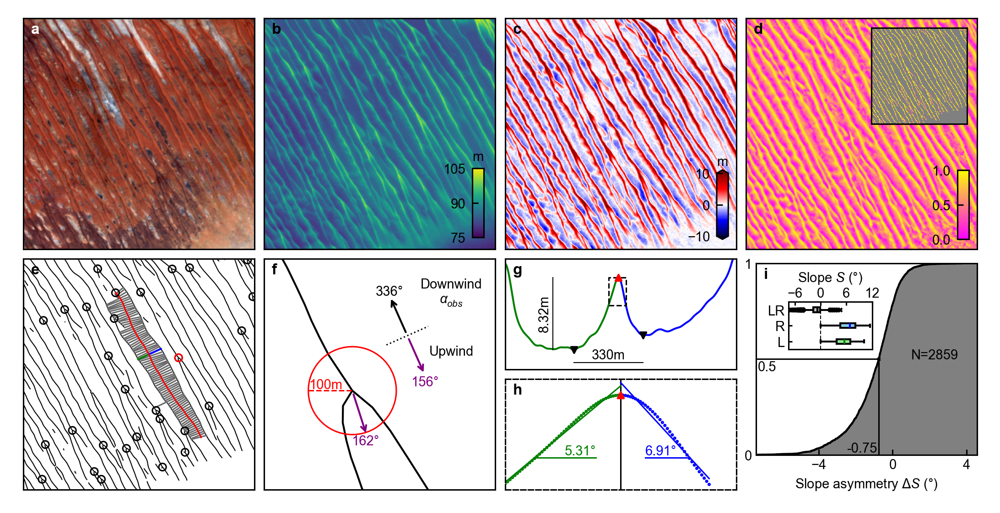

In [43]:
draft = True

### Figure aspect ratio ###
figw,figh = 180/25.4,90/25.4 
figa = figw/figh 

### Buffer for panels ###
bufx = 0.01
bufy = bufx*figa

### Tick buffer ###
tickoffsetx = (fs/72)/figw+plt.rcParams['ytick.major.size']/72/figw
tickoffsety = tickoffsetx*figa

### Label definitions ###
labc = 'lower'
labx = (fs+1)/2/72/figw
laby = labx*figa*(2+(0 if labc=='lower' else 0.5))
labs = ['a','b','c','d','','e','f','g','h','i',''] 

# tick params
tparam = dict(axis='both', which='both',length=0,labelbottom=False,labelleft=False,bottom=False,left=False,top=False,right=False)

### Panel definitons ###
ax0w = (1-bufx*5)/4
ax0h = ax0w*figa
ax0l,ax0b = bufx,2*bufy+ax0h
ax1l,ax1b,ax1w,ax1h = ax0l+ax0w+bufx,ax0b,ax0w,ax0h
ax2l,ax2b,ax2w,ax2h = ax0l+2*ax0w+2*bufx,ax0b,ax0w,ax0h
ax3l,ax3b,ax3w,ax3h = ax0l+3*ax0w+3*bufx,ax0b,ax0w,ax0h
ax3il,ax3ib,ax3iw,ax3ih = ax3l+ax0w/2+bufx,ax3b+ax0h/2+bufy,ax0w/2-2*bufx,ax0h/2-2*bufy
ax4l,ax4b,ax4w,ax4h = ax0l,ax0b-ax0h-bufy,ax0w,ax0h
ax5l,ax5b,ax5w,ax5h = ax0l+ax0w+bufx,ax0b-ax0h-bufy,ax0w,ax0h
ax6l,ax6b,ax6w,ax6h = ax0l+2*ax0w+2*bufx,ax0b-ax0h/2-bufy+bufy/2,ax0w,ax0h/2-bufy/2
ax7l,ax7b,ax7w,ax7h = ax0l+2*ax0w+2*bufx,ax0b-ax0h-bufy,ax0w,ax0h/2-bufy/2
ax8l,ax8b,ax8w,ax8h = (ax0l+3*ax0w+3*bufx+3.5/72/figw+fs/4/72/figw,ax0b-ax0h-bufy+tickoffsety+fs/72/figh+0.01/2,ax0w-(3.5/72/figw+fs/4/72/figw),ax0h-tickoffsety-fs/3/72/figh-fs/72/figh-0.01/2)
ax8il,ax8ib,ax8iw,ax8ih = (ax8l+2*bufx+fs/72/figw,ax8b+ax8h*0.55,ax8w/3+bufx,ax8b+ax8h-3*bufy-(ax8b+ax8h*0.6))

### Colorbar defninitons ###
cax1l,cax1b,cax1w,cax1h = ax1l+ax1w-0.1*ax1w,ax1b+0.05*ax1h,0.05*ax1w,0.3*ax1h
cax2l,cax2b,cax2w,cax2h = ax2l+ax2w-2*bufx,ax2b+bufy,cax1w,cax1h
cax3l,cax3b,cax3w,cax3h = ax3l+ax3w-2*bufx,ax3b+bufy,cax1w,cax1h

### PLOTTING ###
fig = plt.figure(figsize=(figw,figh)) 

### SAT ###
ax = fig.add_axes([ax0l,ax0b,ax0w,ax0h])
show(np.flip(satimg,1),transform=cop_transform,ax=ax,adjust=True,extent=[coplon[0],coplon[-1],coplat[-1],coplat[0]],rasterized=True)
ax.tick_params(**tparam)

### COP
ax = fig.add_axes([ax1l,ax1b,ax1w,ax1h])
pcmCOP = ax.imshow(np.flipud(copimg),cmap="viridis",vmin=75,vmax=105,extent=[coplon[0],coplon[-1],coplat[-1],coplat[0]],rasterized=True)
ax.tick_params(**tparam)

### RR ###
ax = fig.add_axes([ax2l,ax2b,ax2w,ax2h])
pcmRR = ax.imshow(np.flipud(RRimg),cmap="seismic",vmin=-10,vmax=10,extent=[RRlon[0],RRlon[-1],RRlat[-1],RRlat[0]],rasterized=True)
ax.tick_params(**tparam)

### VO ###
ax = fig.add_axes([ax3l,ax3b,ax3w,ax3h])
pcmVO = ax.imshow(np.flipud(VOimg),cmap="spring",vmin=0,vmax=1,extent=[VOlon[0],VOlon[-1],VOlat[-1],VOlat[0]],rasterized=True)
ax.tick_params(**tparam)

### VOmask ###
ax = fig.add_axes([ax3il,ax3ib,ax3iw,ax3ih])
ax.set_facecolor('grey')
pcmVOmask = ax.imshow(np.flipud(VOmaskimg),cmap="spring",vmin=0,vmax=1,extent=[VOmasklon[0],VOmasklon[-1],VOmasklat[-1],VOmasklat[0]],interpolation="none",rasterized=True)
ax.tick_params(**tparam)

### Extracted crestlines with example crest, transects and Y-junctions ###
ax = fig.add_axes([ax4l,ax4b,ax4w,ax4h])
SKLmith.plot(lw=0.5,color="k",ax=ax,zorder=0)
for tempidx,row in trans100.iterrows():
    if tempidx==46:
        ax.plot([row.left_neighbour_4326.x,row.centroids_4326.x],[row.left_neighbour_4326.y,row.centroids_4326.y],color="green",lw=1,ls="solid")
        ax.plot([row.centroids_4326.x,row.right_neighbour_4326.x],[row.centroids_4326.y,row.right_neighbour_4326.y],color="blue",lw=1,ls="solid")
    else:
        ax.plot([row.left_neighbour_4326.x,row.centroids_4326.x],[row.left_neighbour_4326.y,row.centroids_4326.y],color="dimgrey",ls="solid")
        ax.plot([row.centroids_4326.x,row.right_neighbour_4326.x],[row.centroids_4326.y,row.right_neighbour_4326.y],color="dimgrey",ls="solid")
ax.plot(lx,ly,color="red",zorder=2)
SKLYJmith.plot(edgecolor="black",facecolor="none",ax=ax,zorder=3,markersize=15,lw=lw)
SKLYJmith.loc[[1244626]].plot(edgecolor="red",facecolor="none",ax=ax,zorder=4,markersize=15,lw=lw)
ax.axis("square")
ax.set_xlim([coplon[0],coplon[-1]])
ax.set_ylim([coplat[-1],coplat[0]])
ax.tick_params(**tparam)

### AX5 Yjunction
ax = fig.add_axes([ax5l,ax5b,ax5w,ax5h])
ax.tick_params(**tparam)
xc = SKLYJmith.to_crs(3577).loc[[1244626]].geometry.x.values
yc = SKLYJmith.to_crs(3577).loc[[1244626]].geometry.y.values
yjlines.plot(ax=ax,color="k",lw=1)
ax.plot([xc-100,xc],[yc,yc],ls="dashed", color="red")
ax.text(xc-60,yc+5,"100m", color="red", ha="center")
ax.text(100*np.cos(bdir100)+xc,100*np.sin(bdir100)+yc-20,str((90-int(np.round(180/np.pi*bdir100,0)))%360)+"°", color="purple", ha="center",va="center",)
SKLYJmith.to_crs(3577).loc[[1244626]].buffer(100).exterior.plot(ax=ax, color="red")

x0A = xc+125
y0A = yc+125
x1A = 100*np.cos(mithang) + xc + 125
y1A = 100*np.sin(mithang) + yc + 125
x0B = xc
y0B = yc
x1B = 110*np.cos(bdir100)+xc
y1B = 110*np.sin(bdir100)+yc
x0C = xc+125
y0C = yc+125
x1C = 100*np.cos(mithbdir) + xc + 125
y1C = 100*np.sin(mithbdir) + yc + 125

ax.annotate("", xy=(x1A, y1A), xytext=(x0A, y0A),arrowprops=dict(arrowstyle="->", color="k"))
ax.annotate("", xy=(x1B, y1B), xytext=(x0B, y0B),arrowprops=dict(arrowstyle="->", color="purple"))
ax.annotate("", xy=(x1C, y1C), xytext=(x0C, y0C),arrowprops=dict(arrowstyle="->", color="purple"))
ax.plot([-52*np.cos(mithang-np.pi/2)+xc+125,52*np.cos(mithang-np.pi/2)+xc+125],[-52*np.sin(mithang-np.pi/2)+yc+125,52*np.sin(mithang-np.pi/2)+yc+125],color="k",ls="dotted",lw=lw)
ax.text(x1A,y1A,str((90-int(np.round(180/np.pi*mithang,0)))%360)+"°",ha="center")
ax.text(x1C,y1C,str((90-int(np.round(180/np.pi*mithbdir,0)))%360)+"°",ha="center",va="top", color="purple")
ax.text(xc+225,yc+200,"Downwind\n$\\alpha_{obs}$",ha="center")
ax.text(xc+225,yc+80,"Upwind",ha="center")
ax.set_xlim(xc-200,xc+325)
ax.set_ylim(yc-225,yc+300)

### AX6 Transect big
ax = fig.add_axes([ax6l,ax6b,ax6w,ax6h])
ax.tick_params(**tparam)
ax.plot(transect_x[:transect_idx[1]+1],extransinter[:transect_idx[1]+1],color="green",zorder=1,lw=1)
ax.plot(transect_x[transect_idx[1]:],extransinter[transect_idx[1]:],color="blue",zorder=2,lw=1)
ax.scatter(transect_x[transect_idx[0]],extransinter[transect_idx[0]],zorder=3,s=10,color="k",marker="v")
ax.scatter(transect_x[transect_idx[1]],extransinter[transect_idx[1]],zorder=3,s=10,color="red",marker="^")
ax.scatter(transect_x[transect_idx[2]],extransinter[transect_idx[2]],zorder=3,s=10,color="k",marker="v")
ax.plot([iso_x.min(),iso_x.max(),iso_x.max(),iso_x.min(),iso_x.min()],[iso_y.min(),iso_y.min(),iso_y.max(),iso_y.max(),iso_y.min()],ls="dashed",color="k",lw=lw)
ax.plot([transect_x[transect_idx[0]],transect_x[transect_idx[-1]]],[80,80],color="k",lw=0.5)
ax.plot([transect_x[transect_idx[0]]-100,transect_x[transect_idx[0]]-100],[extransinter[transect_idx[0]],extransinter[transect_idx[1]]],color="k",lw=0.5)
ax.text(transect_x[transect_idx[0]]-(transect_x[transect_idx[0]]-transect_x[transect_idx[-1]])/2,80.5,str(round(abs(transect_x[transect_idx[0]]-transect_x[transect_idx[-1]]),2))+"m",ha="center")
ax.text(transect_x[transect_idx[0]]-170,extransinter[transect_idx[1]]-(extransinter[transect_idx[1]]-extransinter[transect_idx[0]])/2,str(round(abs(extransinter[transect_idx[1]]-extransinter[transect_idx[-1]]),2))+"m",va="center",rotation="vertical")
ax.set_ylim([-max(abs(transect_x)),max(abs(transect_x))])
ax.set_ylim([79,95])

### AX7 Transect zoomed
ax = fig.add_axes([ax7l,ax7b,ax7w,ax7h])
ax.tick_params(**tparam)
ax.scatter(iso_x[:iso_pidx+1],iso_y[:iso_pidx+1],edgecolor="green",facecolor="none",s=0.5)
ax.scatter(iso_x[iso_pidx:],iso_y[iso_pidx:],edgecolor="blue",facecolor="none",s=0.5)
ax.scatter(iso_x[iso_pidx],iso_y[iso_pidx],color="red",marker="^",s=10)
ax.axvline(0,color="k",lw=lw,zorder=0)
ax.plot(iso_x[:iso_pidx+1],iso_x[:iso_pidx+1]*lfit[0]+lfit[1],color="green",ls="solid")
ax.plot(iso_x[iso_pidx:],iso_x[iso_pidx:]*rfit[0]+rfit[1],color="blue",ls="solid")
ax.plot([-35,-10],[-35*lfit[0]+lfit[1],-35*lfit[0]+lfit[1]],color="green",lw=lw)
ax.plot([28,10],[-35*lfit[0]+lfit[1],-35*lfit[0]+lfit[1]],color="blue")
ax.text(-10,-35*lfit[0]+lfit[1],str(np.round(180/np.pi*abs(lfit[0]),2))+"°",ha="right",va="bottom", color="green")
ax.text(10,-35*lfit[0]+lfit[1],str(np.round(180/np.pi*abs(rfit[0]),2))+"°",ha="left",va="bottom", color="blue")
ax.set_xlim([-max(abs(iso_x)),max(abs(iso_x))])
ax.set_ylim([88,93])
ax.spines['bottom'].set_linestyle("dashed")
ax.spines['left'].set_linestyle("dashed")
ax.spines['top'].set_linestyle("dashed")
ax.spines['right'].set_linestyle("dashed")

### Histogram ###
ax = fig.add_axes([ax8l,ax8b,ax8w,ax8h])
ax.set_xticks([-4,0,4])
ax.set_yticks([0,1])
ax.stairs(cumhist,bedge,fill=True,facecolor="grey",edgecolor="black")
ax.plot(bedge[1:]-(bedge[1]-bedge[0])/2,cumhist,color="k",lw=1)
ax.hlines(0.5,bedge[0],np.median(data),color="k")
ax.vlines(np.median(data),0,0.5,color="k")
ax.scatter(np.median(data),0.5,zorder=10,marker="x",color="k")
ax.text(np.median(data)-0.1,0,np.round(np.median(data),2),ha="right",va="bottom")
ax.text(np.min(data)+0.1,0.5-0.01,0.5,ha="left",va="top")
ax.set_xticks([-4,0,4])
ax.set_yticks([0,1])
ax.set_xlim(bedge[0],bedge[-1])
ax.set_ylim([0,1])
ax.tick_params(axis="both",pad=2,direction="in")
ax.set_xlabel('Slope asymmetry $\\Delta S$ ($°$)',labelpad=3)
ax.text(1,0.5,"N=%d"%(len(data)))

### Boxplot inset ###
ax = fig.add_axes([ax8il,ax8ib,ax8iw,ax8ih])
boxdata = [leftslope, rightslope, leftslope - rightslope]
flierprops = dict(
    marker='x',  
    markersize=2,     
    markerfacecolor='black',
    markeredgecolor='black',
    linestyle='none'
)
bp = ax.boxplot(
    boxdata,
    patch_artist=True,
    flierprops=flierprops,
    vert=False
)

box_colors = ["lightgreen","skyblue","#C0C0C0"]
median_colors = ["green","blue","black"]

for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_edgecolor("black")
    # patch.set_linewidth(1.2)

# Customize median lines
for median, color in zip(bp["medians"], median_colors):
    median.set_color(color)
    # median.set_linewidth(1.5)

# (Optional) Customize whiskers and caps
for whisker in bp["whiskers"]:
    whisker.set_color("black")
    # whisker.set_linewidth(1.0)

for cap in bp["caps"]:
    cap.set_color("black")
    # cap.set_linewidth(1.0)

ax.set_yticklabels(["L", "R", "LR"])
ax.tick_params(axis="x",direction="in",labelsize=fs,length=2,pad=1)
ax.tick_params(axis="y",direction="in",labelsize=fs,length=2,pad=2)
ax.axvline(0,ls="dashed",color="k",lw=0.5)
ax.set_xlabel('Slope $S$ ($°$)',labelpad=3)
ax.set_xticks([-6,0,6,12])
ax.xaxis.set_label_position("top")
ax.xaxis.tick_top()

### Drafting axis and panel labels ###
ax = fig.add_axes([0,0,1,1]) # make a fake full size axis
ax.patch.set_alpha(0) # set its background to have no color since we want to see the stuff behind it!
plt.xticks([])
plt.yticks([])
for i,pan in enumerate(fig.axes[:-1]):
    axl,axb,axh = np.array(pan.get_position().bounds)[[0,1,3]]
    if i==0:
        ax.text(axl+labx,axb+axh-laby,labs[i],ha='left',va='baseline',fontsize=fs+1,fontweight='bold',color='white')
    else:
        ax.text(axl+labx,axb+axh-laby,labs[i],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')

### Colorbars ###
cax = fig.add_axes([cax1l,cax1b,cax1w,cax1h])
cbar = fig.colorbar(pcmCOP,cax=cax,orientation="vertical")
cax.yaxis.tick_left()
cax.xaxis.set_label_position("top")
cax.set_xlabel("m", color="black")
cax.set_yticks([75,90,105])

cax = fig.add_axes([cax2l,cax2b,cax2w,cax2h])
cbar = fig.colorbar(pcmRR,cax=cax,orientation="vertical",extend="both")
cbar.solids.set_rasterized(True)
cax.yaxis.tick_left()
cax.xaxis.set_label_position("top")
cax.set_xlabel("m", color="black")
cax.set_yticks([-10,0,10])

cax = fig.add_axes([cax3l,cax3b,cax3w,cax3h])
cbar = fig.colorbar(pcmVO,cax=cax,orientation="vertical")
cax.yaxis.tick_left()
cax.xaxis.set_label_position("top")
cax.set_yticks([0,0.5,1])

if not draft:
    ax.axis('off')
    fig.savefig('paper_ready_plots/Method_1_workflow_topo.png')
    fig.savefig('paper_ready_plots/Method_1_workflow_topo.pdf')

#### Extended data (Method): Mithaka flux and bedmode workflow

In [6]:
binwidth = np.abs(ds.ua_bin[1]-ds.ua_bin[0])
dhm = ds.sel(longitude=139.7,latitude=-24.7,method="nearest") # Mithaka example cell (same as topography)

### Calculate the flux rose for ut_opt example ###
dhm = dhm.assign(uf=dhm.um_bin*kappa/np.log(z/z0))
dhm = dhm.assign(uc=dhm.uf*(1+beta*dhm.dm*np.abs(np.sin(dhm.ua_bin-dhm.da))))
dhm = dhm.assign(qc_opt=xr.where(dhm.uc>dhm.ut_opt,(dhm.uc**2-dhm.ut_opt**2)*dhm.ut_opt*fluxk,0))
dhm = dhm.assign(qc_opt_sum=dhm.qc_opt.weighted(dhm.histogram_um_ua).sum("um_bin")) # flux rose data for ut_opt

### Calculate the net across crest flux for all
dhm = dhm.assign_coords(do=np.linspace(-np.pi,np.pi,2**7+1))
dhm = dhm.assign(uc=(dhm.um_bin*kappa/np.log(z/z0))*(1+beta*dhm.dm*np.abs(np.sin(dhm.ua_bin-dhm.do))))
dhm = dhm.assign(qa=xr.where(dhm.uc>dhm.ut,(dhm.uc**2-dhm.ut**2)*dhm.ut*fluxk,0))
dhm = dhm.assign(qc=dhm.qa*np.sin(dhm.ua_bin-dhm.do))
dhm = dhm.assign(qac=np.abs(dhm.qc).weighted(dhm.histogram_um_ua).mean(('um_bin','ua_bin')))
dhm = dhm.assign(qnc=dhm.qc.weighted(dhm.histogram_um_ua).mean(('um_bin','ua_bin')))

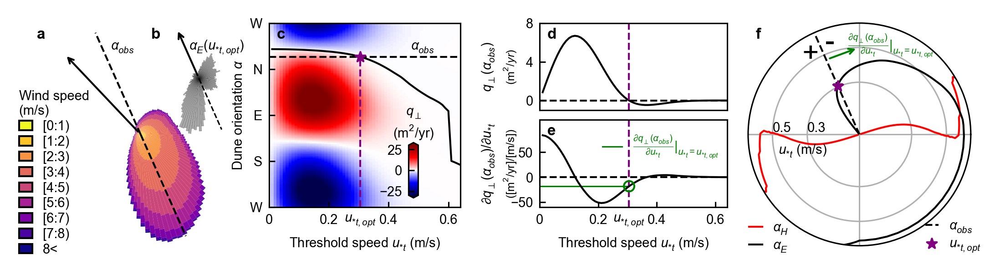

In [11]:
draft = False

### Figure aspect ratio ###
figw = 180/25.4
figh = figw/4
figa = figw/figh 

### Buffer for panels ###
bufx = 0.01
bufy = bufx*figa

### Tick offsets ###
tickoffsetx = (fs/72)/figw+plt.rcParams['ytick.major.size']/72/figw
tickoffsety = tickoffsetx*figa

### Panel labels ###
labc = 'lower'
labx = (fs+1)/2/72/figw
laby = labx*figa*(2+(0 if labc=='lower' else 0.5))
labs = ['a','b','c','d','e','f','g','h','i',''] 

### Tick Params ###
tparam = dict(axis='both', which='both',length=0,labelbottom=False,labelleft=False,bottom=False,left=False,top=False,right=False)

### Define axis ###
ax0w = (1-bufx*5)/4
ax0h = (1-bufy*2)
ax0l,ax0b = bufx,bufy
ax0il,ax0ib,ax0iw,ax0ih = ax0l+ax0w*1/2,ax0b+ax0h*1/2,ax0w*1/2,ax0h*1/2
ax1l,ax1b,ax1w,ax1h = ax0l+ax0w+bufx,ax0b,ax0w,ax0h
ax2l,ax2b,ax2w,ax2h = ax0l+2*ax0w+2*bufx,ax0b+ax0h/2+bufy/2,ax0w,ax0h/2-bufy/2
ax3l,ax3b,ax3w,ax3h = ax0l+2*ax0w+2*bufx,ax0b,ax0w,ax0h/2-bufy/2
ax4l,ax4b,ax4w,ax4h = ax0l+3*ax0w+3*bufx,ax0b,ax0w,ax0h

### PLOTTING ###
fig = plt.figure(figsize=(figw,figh)) 

### Wind rose plot ###
ax = fig.add_axes([ax0l,ax0b,ax0w,ax0h],polar=True)
edges = np.array([0,1,2,3,4,5,6,7,8, np.inf])
hist_coarse = dhm.histogram_um_ua.groupby_bins("um_bin", edges, right=False).sum()
netuf = (dhm.histogram_um_ua.sum("um_bin")*np.exp(1j*dhm.ua_bin)).mean('ua_bin')
netufa = np.arctan2(netuf.imag,netuf.real)
n_bins = len(hist_coarse.um_bin_bins)
colors = plt.cm.plasma_r(np.linspace(0, 1, n_bins))
labels = []
for i in range(n_bins):
    left = hist_coarse.um_bin_bins.values[i].left
    right = hist_coarse.um_bin_bins.values[i].right
    if i == 0:
        label = "[%d:%d)" % (left, right)
        bottom = None
    elif i == n_bins - 1:
        label = "%d<" % left
        bottom = hist_coarse.isel(um_bin_bins=slice(None, i)).sum("um_bin_bins")
    else:
        label = "[%d:%d)" % (left, right)
        bottom = hist_coarse.isel(um_bin_bins=slice(None, i)).sum("um_bin_bins")
    labels.append(label)
    ax.bar(dhm.ua_bin_from,hist_coarse.isel(um_bin_bins=i),width=binwidth,bottom=bottom,color=colors[i])
rmax = ax.get_rmax()
ax.axvline(dhm.da,lw=1,ls="dashed",color="k")
ax.axvline(dhm.da-np.pi,lw=1,ls="dashed",color="k")
ax.annotate("",xy=(netufa, rmax),xytext=(netufa, 0),arrowprops=dict(arrowstyle="->",color="k",lw=1))

### Legend ###
for label, color in zip(labels, colors):
    ax.bar(0, 0, facecolor=color, edgecolor="k",label=label)
ax.legend(loc="lower left",title="Wind speed\n(m/s)",handlelength=1,labelspacing=0.2,alignment="left",bbox_to_anchor=(-0.1,-0.1))
ax.set_xticks([])
ax.axis("off")

### Flux rose plot for ut_opt ###
ax = fig.add_axes([ax0il+0.001,ax0ib,ax0iw,ax0ih],polar=True)
ax.bar(dhm.ua_bin_from,dhm.qc_opt_sum,width=binwidth,lw=0.05,edgecolor="k",facecolor="darkgrey")
rmax = ax.get_rmax()
ax.annotate("",xy=(dhm.da, rmax),xytext=(dhm.da, 0),arrowprops=dict(arrowstyle="->",color="k",lw=1)) # can use dhm.da since it is the one that matches
ax.axvline(dhm.da-np.pi,color="k",ls="dashed")
ax.axis("off")

### ELongation modes as a function of dune orientation ###
ax = fig.add_axes([ax1l+0.004,ax1b+4*bufy,ax1w-4*bufx,ax1h-4*bufy])
pcm = ax.pcolormesh(dhm.ut,dhm.do,dhm.qnc.T*s2y,cmap="seismic",vmin=-30,vmax=30,rasterized=True)
ax.plot(dhm.ut,dhm.ae, color="k",lw=1)
ax.axhline(dhm.da,color="k",ls="dashed",lw=1)
ax.plot([dhm.ut_opt,dhm.ut_opt],[-np.pi,dhm.da],color="purple", ls="dashed", lw=1)
ax.scatter(dhm.ut_opt, dhm.da, marker="*", color="purple",zorder=2,s=30)
ax.set_xlim(0,dhm.ut.max())
ax.set_xticks([0,0.2,dhm.ut_opt,0.4,0.6])
ax.set_xticklabels([0,0.2,"$u_{*t,opt}$",0.4,0.6])
ax.set_ylim([-np.pi,np.pi])
ax.set_yticks([-np.pi,-np.pi/2,0,np.pi/2,np.pi])
ax.set_yticklabels(["W","S","E","N","W"])
# ax.tick_params(axis="both",pad=2,direction="in")
ax.set_xlabel("Threshold speed $u_{*t}$ (m/s)")
ax.set_ylabel("Dune orientation $\\alpha$",va="baseline")

### Across crest flux example ###
ax = fig.add_axes([ax2l+4*bufx-0.004,ax2b+2*bufy,ax2w-4*bufx-0.004,ax2h-2*bufy])
ax.plot(dhm.ut,dhm.qnce*s2y, color="k",lw=1)
ax.axvline(dhm.ut_opt,color="purple",ls="dashed",lw=1)
ax.axhline(0,ls="dashed",color="k",lw=1)
ax.set_xlim(0,dhm.ut.max())
ax.set_xticks([])
ax.set_ylim(-1,8)
ax.set_yticks([0,4,8])
ax.set_ylabel("$q_{\\perp}(\\alpha_{obs})$",va="baseline",labelpad=18)

### Across crest flux derivative example ###
ax = fig.add_axes([ax3l+4*bufx-0.004,ax3b+4*bufy,ax3w-4*bufx-0.004,ax3h-2*bufy])
ax.plot(dhm.ut,dhm.dqncedut*s2y, color="k",zorder=9,lw=1)
ax.set_xlabel("Threshold speed $u_{*t}$ (m/s)")
ax.axhline(0,color="k",ls="dashed",lw=1)
ax.axvline(dhm.ut_opt,color="purple",ls="dashed",lw=1)
ax.plot([0,dhm.ut_opt],[dhm.dqncedut_opt*s2y,dhm.dqncedut_opt*s2y],ls="solid",color="green", label="$\\frac{\\partial q_{\\perp}(\\alpha_{obs}) }{\\partial u_{*t}}|_{u_{*t}=u_{*t,opt}}$")
ax.scatter(dhm.ut_opt,dhm.dqncedut_opt*s2y, facecolor="none", edgecolor="green",marker="o",zorder=10,s=30)
ax.set_ylabel("$\\partial q_{\\perp}(\\alpha_{obs})/\\partial u_{*t}$",va="baseline",labelpad=10)
ax.set_xlim(0,dhm.ut.max())
ax.set_xticks([0,0.2,dhm.ut_opt,0.4,0.6])
ax.set_xticklabels([0,0.2,"$u_{*t,opt}$",0.4,0.6])
ax.legend(frameon=False,labelcolor="green",bbox_to_anchor=(0.27,0.4))
ax.set_ylim(-60,115)
ax.set_yticks([-50,0,50])

### Elongation and bed mode orientation example (polar) ###
ax = fig.add_axes([ax4l,ax4b,ax4w,ax4h],polar=True)
utintp = np.linspace(0.01,0.64,1000)
oblique_break = (np.argwhere(np.diff(dhm.ao)>=(np.pi/2)))[0][0] 
oblique_unsigned = (np.array(list(dhm.ao[:oblique_break+1].values)+list((dhm.ao[oblique_break+1:].values-np.pi)))+2*np.pi)%(2*np.pi)
obliqueintp = np.interp(utintp,dhm.ut,oblique_unsigned,period=2*np.pi)
elonintp = np.interp(utintp,dhm.ut,(dhm.ae+2*np.pi)%(2*np.pi),period=2*np.pi)
ax.plot(obliqueintp,utintp,color="red", label="$\\alpha_{H}$",lw=1)
ax.plot(np.pi+obliqueintp,utintp,color="red",lw=1)
ax.plot(dhm.ae.interp(ut=np.linspace(0.01,0.64,1000),method="linear"),np.linspace(0.01,0.64,1000),color="k",label="$\\alpha_{E}$",lw=1)
ax.axvline(dhm.da,color="k",ls="dashed", label="$\\alpha_{obs}$",lw=1)
ax.annotate("",xy=(np.pi/2, 0.5),xytext=(dhm.da,0.47),arrowprops=dict(arrowstyle="->",color="green",lw=1),color="green") # eyeballed!
ax.scatter(dhm.da, dhm.ut_opt, marker="*", color="purple", zorder=2, label="$u_{*t,opt}$",s=30)
ax.set_rticks([0.3,0.5])
ax.set_rlabel_position(180)
ax.set_xticks([0,np.pi/2,np.pi,1.5*np.pi,2*np.pi/2])
ax.set_xticklabels([])
handles, labels = ax.get_legend_handles_labels()
leg1 = ax.legend(handles[:2],labels[:2],bbox_to_anchor=(-0.05, -0.09),loc="lower left",frameon=False,handlelength=1,labelspacing=0.2,alignment="left")
leg2 = ax.legend(handles[2:],labels[2:],bbox_to_anchor=(1.1, -0.09),loc="lower right",frameon=False,handlelength=1,labelspacing=0.2,alignment="left")
ax.add_artist(leg1)
# ax.legend(frameon=False,loc="lower left",handlelength=1,labelspacing=0.2,alignment="left",bbox_to_anchor=(0, -0.05))

# dummy axes for drafting and panel labels
ax = fig.add_axes([0,0,1,1]) # make a fake full size axis
ax.patch.set_alpha(0) # set its background to have no color since we want to see the stuff behind it!
plt.xticks([])
plt.yticks([])
# ax.axvline(0.5)
for i,pan in enumerate(fig.axes[:-1]):
    axl,axb,axh = np.array(pan.get_position().bounds)[[0,1,3]]
    ax.text(axl+labx,axb+axh-laby,labs[i],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')

### Add some annotation
ax.text(ax0l+0.1,ax0b+ax0h-0.11,"$\\alpha_{obs}$",ha="center",va="baseline")
ax.text(ax1l+ax1w-0.075,ax1b+ax1h-0.11,"$\\alpha_{obs}$",ha="center",va="baseline")
# ax.text(ax0l+0.035,ax0b+ax0h-0.11,"$\\langle u \\rangle$",ha="center",va="baseline")

ax.text(ax0il+0.05,ax0b+ax0h-0.11,"$\\alpha_{E}(u_{*t,opt})$",ha="left",va="baseline")

ax.text(ax2l+bufx-0.004,(ax2b+2*bufy)+(ax2h-2*bufy)/2,"(m$^{2}/yr$)",va="center",ha="center",rotation=90,fontsize=6)
ax.text(ax3l+bufx-0.004,(ax3b+4*bufy)+(ax3h-2*bufy)/2,"([m$^2$/yr]/[m/s])",rotation=90,va="center",ha="center",fontsize=6)

ax.text(ax4l+0.06,0.4,"$u_{*t}$ (m/s)",va="bottom",ha="center")
ax.text(ax4l+ax4w*0.35,0.85,"-",fontsize=15)
ax.text(ax4l+ax4w/4,0.8,"+",fontsize=15)
ax.text(ax4l+ax4w*0.45, 0.85,"$\\frac{\\partial q_{\\perp}(\\alpha_{obs})}{\\partial u_{*t}}|_{u_{*t}=u_{*t,opt}}$",color="green")

### Add colorbar
cb1l,cb1b,cb1w,cb1h = ax1l+(ax1w-4*bufx)-0.25*(ax1w-4*bufx),ax1b+4*bufy+0.05*(ax1h-4*bufy),0.05*(ax1w-4*bufx),0.3*(ax1h-4*bufy)
cax = fig.add_axes([cb1l,cb1b,cb1w,cb1h])
cbar = fig.colorbar(pcm,cax=cax,orientation="vertical",extend="both")
cax.yaxis.tick_left()
# cax.tick_params(**cparam)
cax.set_xlabel("$q_{\\perp}$\n(m$^{2}$/yr)", color="black")
cax.xaxis.set_label_position("top")
cax.set_yticks([-25,0,25])

if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Method_2_workflow_flux_mean.png')
    fig.savefig('paper_ready_plots/Method_2_workflow_flux_mean.pdf')
plt.show()

#### Main text: Crest orientation and dune field location

In [15]:
### Raster to extrapolate dune orienations for streamplot
xx,yy = np.meshgrid(ds.longitude.values,ds.latitude.values) # define once
ras = extrapolate_angles(ds.da.values,boundary="extend")
u = np.cos(ras)
v = np.sin(ras)

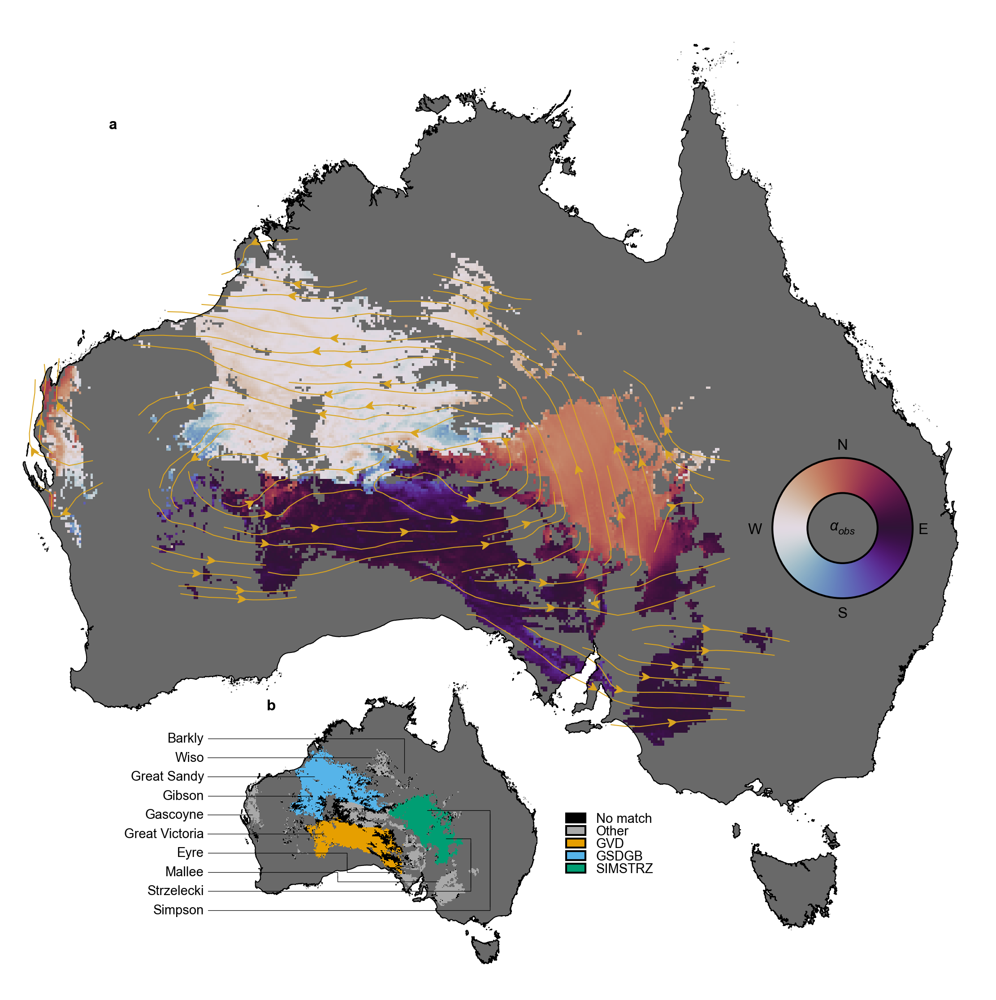

In [105]:
draft = True

### Figure setup ### 
figw,figh = 180/25.4,180/25.4
figa = figw/figh 

### Legend denfinitions ###
labels = ['No match','Other','GVD','GSDGB','SIMSTRZ']
colors = ['black',"darkgrey","#E69F00","#56B4E9","#009E73"]
cmap = ListedColormap(colors[1:])

### Panel labels ###
labc = 'lower'
labx = (fs+1)/2/72/figw
laby = labx*figa*(2+(0 if labc=='lower' else 0.5))

### PLOTTING ###
fig = plt.figure(figsize=(figw,figh)) 

### Dune whorl orienation map
ax = fig.add_axes([0,0.03,1,1])
ax.pcolormesh(ds.longitude,ds.latitude,ds.da, cmap="twilight", vmin=-np.pi, vmax=np.pi, rasterized=True)
ax.streamplot(xx,yy,u,v, density=2, color='goldenrod', arrowstyle='fancy', arrowsize=1 ,linewidth=0.5)
ax_color = ax.inset_axes([0.72,0.3,0.3,0.3], transform=ax.transAxes)
round_colorbar(ax_color, "twilight") 
ax_color.set_axis_off()
ax.text(0.72+0.3/2,0.3+0.3/2,"$\\alpha_{obs}$",transform=ax.transAxes,ha="center",va="center",fontsize=8)
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Dune field overview map ###
ax = fig.add_axes([0.2,0.01,0.35,0.35]) 
ax.pcolormesh(ds.longitude,ds.latitude,ds.dune_mask.where(ds.dune_mask),cmap="Greys_r",rasterized=True)
ax.pcolormesh(ds.longitude,ds.latitude,(ds.dune_mask.where(ds.dune_mask)*0+ds.GVD*1+ds.GSDGB*2+ds.SIMSTRZ*3).where(~np.isnan(ds.ut_opt)),cmap=cmap, vmin=-0.5, vmax=3.5,rasterized=True)
handles = [mpatches.Patch(facecolor=colors[i],edgecolor="k", label=labels[i]) for i in range(len(labels))]
ax.legend(handles=handles,loc='lower left',bbox_to_anchor=(1.05, 0.25), ncols=1,frameon=False,facecolor='white',edgecolor='none',labelspacing=0)
AUS_back(ax)
ax.axis("off")

### Draft axis ###
ax = fig.add_axes([0,0,1,1]) 
ax.patch.set_alpha(0)
plt.xticks([])
plt.yticks([])

### Panel labels ###
ax.text(0.1,0.9,"a",ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(0.275,0.29,"b",ha='right',va='baseline',fontsize=fs+1,fontweight='bold')

### Dune field labels ###
ax.text(0.2,0.26,"Barkly",ha='right',va='center',fontsize=fs)
ax.text(0.2,0.24,"Wiso",ha='right',va='center',fontsize=fs)
ax.text(0.2,0.22,"Great Sandy",ha='right',va='center',fontsize=fs)
ax.text(0.2,0.2,"Gibson",ha='right',va='center',fontsize=fs)
ax.text(0.2,0.18,"Gascoyne",ha='right',va='center',fontsize=fs)
ax.text(0.2,0.16,"Great Victoria",ha='right',va='center',fontsize=fs)
ax.text(0.2,0.14,"Eyre",ha='right',va='center',fontsize=fs)
ax.text(0.2,0.12,"Mallee",ha='right',va='center',fontsize=fs)
ax.text(0.2,0.10,"Strzelecki",ha='right',va='center',fontsize=fs)
ax.text(0.2,0.08,"Simpson",ha='right',va='center',fontsize=fs)

### Dune field annotations ### 
ax.annotate("",xy=(0.41, 0.22), xytext=(0.2, 0.26),arrowprops=dict(arrowstyle="-", color="k", lw=0.3,connectionstyle="angle,angleA=0,angleB=90,rad=0"))
ax.annotate("",xy=(0.38, 0.24), xytext=(0.2, 0.24),arrowprops=dict(arrowstyle="-", color="k", lw=0.3))
ax.annotate("",xy=(0.32, 0.22), xytext=(0.2, 0.22),arrowprops=dict(arrowstyle="-", color="k", lw=0.3))
ax.annotate("",xy=(0.31, 0.19), xytext=(0.2, 0.20),arrowprops=dict(arrowstyle="-", color="k", lw=0.3,connectionstyle="angle,angleA=0,angleB=90,rad=0"))
ax.annotate("",xy=(0.255, 0.18), xytext=(0.2, 0.18),arrowprops=dict(arrowstyle="-",color="k", lw=0.3))
ax.annotate("",xy=(0.33, 0.16), xytext=(0.2, 0.16),arrowprops=dict(arrowstyle="-", color="k", lw=0.3))
ax.annotate("",xy=(0.35, 0.12), xytext=(0.2, 0.14),arrowprops=dict(arrowstyle="-", color="k", lw=0.3,connectionstyle="angle,angleA=0,angleB=90,rad=0"))
ax.annotate("",xy=(0.41, 0.12), xytext=(0.35, 0.14),arrowprops=dict(arrowstyle="-",color="k", lw=0.3,connectionstyle="angle,angleA=90,angleB=0,rad=0"))
ax.annotate("",xy=(0.34, 0.11), xytext=(0.2, 0.12),arrowprops=dict(arrowstyle="-", color="k", lw=0.3,connectionstyle="angle,angleA=0,angleB=90,rad=0"))
ax.annotate("",xy=(0.45, 0.11), xytext=(0.34, 0.12),arrowprops=dict(arrowstyle="-",color="k", lw=0.3,connectionstyle="angle,angleA=90,angleB=0,rad=0"))
ax.annotate("",xy=(0.48, 0.155), xytext=(0.2, 0.1),arrowprops=dict(arrowstyle="-", color="k", lw=0.3,connectionstyle="angle,angleA=0,angleB=90,rad=0"))
ax.annotate("",xy=(0.45, 0.155), xytext=(0.48, 0.1),arrowprops=dict(arrowstyle="-",color="k", lw=0.3,connectionstyle="angle,angleA=90,angleB=0,rad=0"))
ax.annotate("",xy=(0.5, 0.185), xytext=(0.2, 0.08),arrowprops=dict(arrowstyle="-", color="k", lw=0.3,connectionstyle="angle,angleA=0,angleB=90,rad=0"))
ax.annotate("",xy=(0.43, 0.185), xytext=(0.5, 0.08),arrowprops=dict(arrowstyle="-",color="k", lw=0.3,connectionstyle="angle,angleA=90,angleB=0,rad=0"))

# ax.text(0.2355,0.218,"Gascoyne",ha='center',va='baseline',fontsize=fs)
# ax.text(0.33,0.21,"Great\nSandy",ha='center',va='baseline',fontsize=fs)
# ax.text(0.38,0.25,"Wiso",ha='center',va='baseline',fontsize=fs)
# ax.text(0.42,0.22,"Barkly",ha='center',va='baseline',fontsize=fs)
# ax.text(0.42,0.179,"Simpson",ha='center',va='baseline',fontsize=fs)
# ax.text(0.35,0.153,"Great Victoria",ha='center',va='baseline',fontsize=fs)
# ax.text(0.47,0.15,"Strzelecki",ha='center',va='baseline',fontsize=fs)
# ax.text(0.46,0.099,"Mallee",ha='center',va='baseline',fontsize=fs)
# ax.text(0.395,0.099,"Eyre",ha='center',va='baseline',fontsize=fs)
# ax.text(0.29,0.176,"Gibson",ha='center',va='baseline',fontsize=fs)

if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Main_1_orientation_overview.png')
    fig.savefig('paper_ready_plots/Main_1_orientation_overview.pdf')
    
plt.show()

#### Main text: Vegetation cover and threshold speed

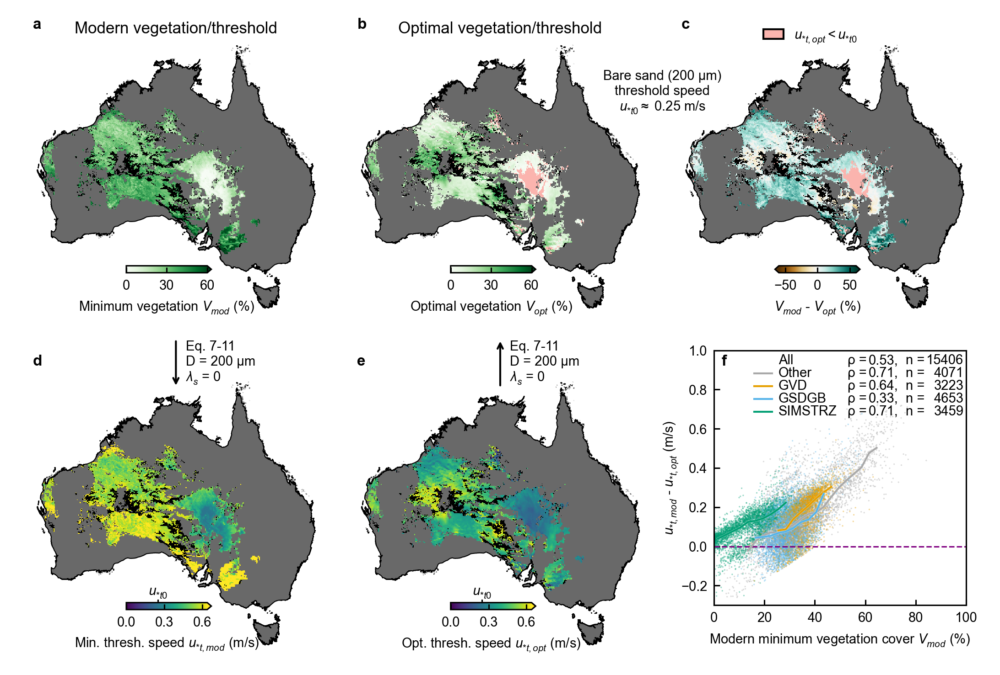

In [12]:
draft = False

### Get a color for ut_opt<ut_200 microns ###
cmap = plt.get_cmap("Pastel1")
but0c = cmap(0.0)

### Figure specs ###
figw,figh = 180/25.4,120/25.4 
figa = figw/figh

### Label definitions ###
labc = 'lower'
labx = (fs+1)/2/72/figw
laby = labx*figa*(2+(0 if labc=='lower' else 0.5))
labs = ['a','b','c','d','e','f','g','h','i'] 

### Legend definitions ###
labels = ['No match','Other','GVD','GSDGB','SIMSTRZ']
colors = ['black',"darkgrey","#E69F00","#56B4E9","#009E73"]
cmap = ListedColormap(colors[1:])

### Panel buffers (could do with a clean up) ###
xoffl=0.05771995659722229
xoffr=0.011465277777777727
yoffb=0.06155972222222222
yofft=0.0077611111111111075
bufx = 0.01
bufy = bufx*figa

### Set up axes for Panels (could do with a clean up) ###
ax0w = (1-2*xoffr-2*bufx)/3
ax0h = ax0w*figa
ax0l,ax0b = xoffr,1-fs/2/72-ax0h
ax1l,ax1b,ax1w,ax1h = ax0l+ax0w+bufx,ax0b,ax0w,ax0h
ax2l,ax2b,ax2w,ax2h = 2/3+xoffl+0.00035277777777786845-0.005038475115740848,yoffb,1/3-xoffl-xoffr+0.005038475115740848,0.5-yoffb
ax3l,ax3b,ax3w,ax3h = xoffr,yoffb,ax0w,ax0h
testoff=1-(2/3+xoffl+0.00035277777777786845-0.005038475115740848+1/3-xoffl-xoffr+0.005038475115740848)+0.01

### PLOTTING ###
fig = plt.figure(figsize=(figw,figh)) 

### Top left panel: modern minimum vegetation cover
ax = fig.add_axes([testoff,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude,ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.tot_cov.min("time").where(~np.isnan(ds.ut_opt)), cmap="Greens",vmin=0,vmax=60,rasterized=True)
# cax = ax.inset_axes([0.25,0.2,0.3,0.025], transform=ax.transAxes)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05, extend="max")
cbar.ax.set_xticks([0,30,60])
cbar.ax.set_xlabel('Minimum vegetation $V_{mod}$ (%)')
AUS_back(ax)
ax.set_title("Modern vegetation/threshold",va="top")
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Top middle panel: inferred vegetation cover from ut_opt ###
ax = fig.add_axes([testoff+1/3,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude,ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
ax.pcolormesh(ds.longitude,ds.latitude,xr.where(np.isnan(ds.tot_cov_opt)&(~np.isnan(ds.ut_opt)),1,np.nan),cmap="Pastel1",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.tot_cov_opt,cmap="Greens",vmin=0,vmax=60,rasterized=True)
# cax = ax.inset_axes([0.25,0.2,0.3,0.025], transform=ax.transAxes)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05, extend="max")
cbar.ax.set_xticks([0,30,60])
cbar.ax.set_xlabel('Optimal vegetation $V_{opt}$ (%)')
# handles = [mpatches.Patch(facecolor=but0c,edgecolor="k", label='$u_{*t,opt}<u_{*t0}$')]
# ax.legend(handles=handles,loc='lower center',bbox_to_anchor=(0.45, 0.925), frameon=False,facecolor='white',edgecolor='none',labelspacing=0)
ax.set_xticks([])
ax.set_yticks([])
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.set_title("Optimal vegetation/threshold",va="top")
AUS_back(ax)
ax.axis("off")

### Top right panel: vegetation difference modern and optimal
ax = fig.add_axes([testoff+2/3,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude,ds.dune_mask.where(ds.dune_mask),cmap="Greys_r",rasterized=True)
ax.pcolormesh(ds.longitude,ds.latitude,xr.where(np.isnan(ds.tot_cov_opt)&(~np.isnan(ds.ut_opt)),1,np.nan),cmap="Pastel1",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.tot_cov.min("time")-ds.tot_cov_opt,cmap="BrBG",vmin=-60,vmax=60,rasterized=True)
# cax = ax.inset_axes([0.25,0.2,0.3,0.025], transform=ax.transAxes)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05, extend="both")
cbar.ax.set_xlabel('$V_{mod}$ - $V_{opt}$ (%)')
handles = [mpatches.Patch(facecolor=but0c, edgecolor="k", label='$u_{*t,opt}<u_{*t0}$')]
ax.legend(handles=handles,loc='lower center',bbox_to_anchor=(0.45, 0.925), frameon=False,facecolor='white',edgecolor='none',labelspacing=0)
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Bottom left panel: threshold speed inferred from modern minimum vegetation cover for 200 micron sands
ax = fig.add_axes([testoff,0+0.0038805555555555538 -0.02,1/3-2*testoff,1/2-yofft])
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.ut_mod.where(~np.isnan(ds.ut_opt)), vmin=0, vmax=0.64, cmap="viridis",rasterized=True)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05, extend="max")
cax.axvline(x=ut0(200e-6), color='k', linewidth=0.75, ymin=1.1, ymax=1.4,clip_on=False)
cax.text(ut0(200e-6), 1.4, '$u_{*t0}$',color='k',ha='center', va='bottom',transform=cax.get_xaxis_transform())
cbar.ax.set_xticks([0,0.3,0.6])
cbar.ax.set_xlabel('Min. thresh. speed $u_{*t,mod}$ (m/s)')
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Bottom middle panel: optimal threshold speed
ax = fig.add_axes([testoff+1/3,0+0.0038805555555555538-0.02,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.ut_opt.where(~np.isnan(ds.ut_opt)), vmin=0, vmax=0.64, cmap="viridis",rasterized=True)
# cax = ax.inset_axes([0.25,0.2,0.3,0.025], transform=ax.transAxes)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05, extend="max")
cax.axvline(x=ut0(200e-6), color='k', linewidth=0.75, ymin=1.1, ymax=1.4,clip_on=False)
cax.text(ut0(200e-6), 1.4, '$u_{*t0}$',color='k',ha='center', va='bottom',transform=cax.get_xaxis_transform())
cbar.ax.set_xlabel('Opt. thresh. speed $u_{*t,opt}$ (m/s)')
cbar.ax.set_xticks([0,0.3,0.6])
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Bottom right panel: modern and optimal threshold speed difference over modern minimum vegetation cover
ax = fig.add_axes([ax2l,ax2b+0.045-0.02,ax2w-0.01,ax2h-0.045])
regmask = ((~np.isnan(ds.ut_opt)&ds.GVD)*2+(~np.isnan(ds.ut_opt)&ds.GSDGB)*3+(~np.isnan(ds.ut_opt)&ds.SIMSTRZ)*4)
regmask = xr.where((~np.isnan(ds.ut_opt)&(regmask==0)),1,regmask)
regscat = pd.concat([ds.tot_cov.min("time").to_dataframe(),(ds.ut_mod-ds.ut_opt).to_dataframe("delta_ut"),regmask.to_dataframe("region")],axis=1).dropna().sample(frac=1,random_state=10)
regscat["region_color"] = [colors[i] for i in regscat.region]
halo = [pe.withStroke(linewidth=1.1, foreground="white")]
ax.scatter(regscat.tot_cov, regscat.delta_ut, c=regscat.region_color,marker="x", s=0.1, alpha=0.4, zorder=1)
ax.axhline(0, color="purple", ls="dashed",zorder=2)
rho_all, _ = stats.spearmanr(regscat.tot_cov, regscat.delta_ut)
rows = [("All", rho_all, len(regscat), None)]
for i in range(1, len(labels)):
    g = regscat[regscat.region == i]
    rho, _ = stats.spearmanr(g.tot_cov, g.delta_ut)
    xb, yb, q25, q75 = bin_veg_ut(g.delta_ut.values, g.tot_cov.values, n_points=50)
    ax.plot(xb, yb, color=colors[i], lw=1, path_effects=halo, zorder=3)
    rows.append((labels[i], rho, len(g), colors[i]))

# column positions in axes coordinates (tweak to taste)
x_line = (0.16, 0.23)   # line sample start/end
x_name = 0.255          # region name, left-aligned
x_rholab, x_rho = 0.53, 0.73   # "ρ=" left-aligned, value right-aligned
x_nlab, x_n = 0.76, 0.99       # "n=" left-aligned, count right-aligned
y0, dy = 0.96, 0.05

for k, (name, rho, n, c) in enumerate(rows):
    y = y0 - k*dy
    kw = dict(transform=ax.transAxes, va="center", zorder=5)
    if c is not None:
        ax.plot(x_line, [y, y], color=c, lw=1, transform=ax.transAxes,
                clip_on=False, zorder=5)
    ax.text(x_name,   y, name,          ha="left",  **kw)
    ax.text(x_rholab, y, "ρ = ",          ha="left",  **kw)
    ax.text(x_rho,    y, f"{rho:.2f},",  ha="right", **kw)
    ax.text(x_nlab,   y, "n = ",          ha="left",  **kw)
    ax.text(x_n,      y, f"{n}",        ha="right", **kw)
ax.set_xlabel('Modern minimum vegetation cover $V_{mod}$ (%)')
ax.set_ylabel('$u_{*t,mod}$ - $u_{*t,opt}$ (m/s)', va="baseline")
ax.set_xlim(0,100)
ax.set_ylim(-0.3,1)


### Draft axis and annotations
ax = fig.add_axes([0,0,1,1]) 
ax.annotate("",xy=(1/6, 1/2-0.05-0.03),xytext=(1/6, 1/2),arrowprops=dict(arrowstyle="->",color="k",lw=1))
ax.annotate("",xy=(1/2, 1/2),xytext=(1/2, 1/2-0.05-0.03),arrowprops=dict(arrowstyle="->",color="k",lw=1))
ax.text(2/3,0.85,"Bare sand (200 μm)\nthreshold speed\n$u_{*t0} \\approx$ %.2f m/s"%(ut0(200e-6)),ha="center")
ax.text(1/6+0.01,0.46,"Eq. 7-11\nD = 200 μm\n$\\lambda_s$ = 0",va="center",ha="left")
ax.text(1/2+0.01,0.46,"Eq. 7-11\nD = 200 μm\n$\\lambda_s$ = 0",va="center",ha="left")
ax.text(0+labx*2.5,1-laby,labs[0],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(1/3+labx*2.5,1-laby,labs[1],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(2/3+labx*2.5,1-laby,labs[2],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(labx*2.5,1/2-laby-0.02,labs[3],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(1/3+labx*2.5,1/2-laby-0.02,labs[4],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(2/3+xoffl+0.00035277777777786845-0.005038475115740848+labx,1/2-laby-0.02,labs[5],ha='left',va='baseline',fontsize=fs+1,fontweight='bold') # inside the scatter plot
ax.patch.set_alpha(0)
plt.xticks([])
plt.yticks([])
if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Main_2_vegetation_threshold.png')
    fig.savefig('paper_ready_plots/Main_2_vegetation_threshold.pdf')

#### Main text: Slope and derivatives

In [7]:
### Extrapolate the potential reorganization and slope asymmetry angles for streamplots
xxm, yym = np.meshgrid(ds.longitude,ds.latitude) # define once
rasopt = extrapolate_angles(ds.dr_opt.where(~np.isnan(ds.ut_opt)&(ds.ut_max>=ds.ut_opt)).values,boundary="extend")
rasslp = extrapolate_angles(ds.dr_slp.values,boundary="extend")
rasmod = extrapolate_angles(ds.dr_mod.where(~np.isnan(ds.ut_opt)&(ds.ut_max>=ds.ut_mod)).values,boundary="extend")
uopt = np.cos(rasopt)
vopt = np.sin(rasopt)
uslp = np.cos(rasslp)
vslp = np.sin(rasslp)
umod = np.cos(rasmod)
vmod = np.sin(rasmod)

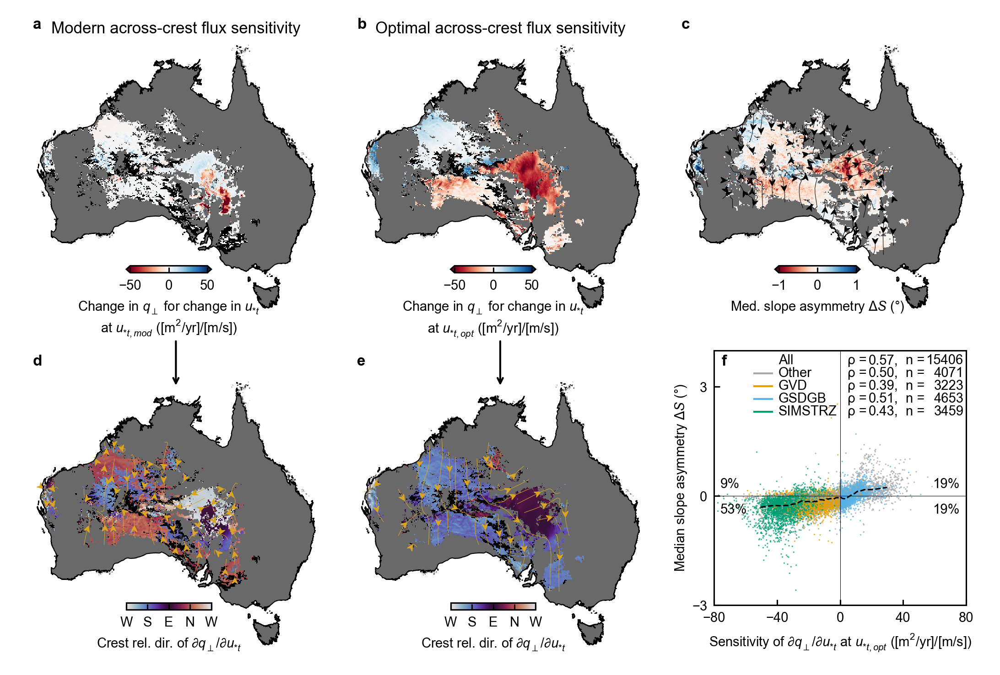

In [9]:
draft = False

### Get a color for ut_opt<ut_200 microns ###
cmap = plt.get_cmap("Pastel1")
but0c = cmap(0.0)

### Figure specs ###
figw,figh = 180/25.4,120/25.4 
figa = figw/figh

### Label definitions ###
labc = 'lower'
labx = (fs+1)/2/72/figw
laby = labx*figa*(2+(0 if labc=='lower' else 0.5))
labs = ['a','b','c','d','e','f','g','h','i'] 

### Legend definitions ###
labels = ['No match','Other','GVD','GSDGB','SIMSTRZ']
colors = ['black',"darkgrey","#E69F00","#56B4E9","#009E73"]
cmap = ListedColormap(colors[1:])

### Panel buffers (could do with a clean up) ###
xoffl=0.05771995659722229
xoffr=0.011465277777777727
yoffb=0.06155972222222222
yofft=0.0077611111111111075
bufx = 0.01
bufy = bufx*figa

### Set up axes for Panels (could do with a clean up) ###
ax0w = (1-2*xoffr-2*bufx)/3
ax0h = ax0w*figa
ax0l,ax0b = xoffr,1-fs/2/72-ax0h
ax1l,ax1b,ax1w,ax1h = ax0l+ax0w+bufx,ax0b,ax0w,ax0h
ax2l,ax2b,ax2w,ax2h = 2/3+xoffl+0.00035277777777786845-0.005038475115740848,yoffb,1/3-xoffl-xoffr+0.005038475115740848,0.5-yoffb
ax3l,ax3b,ax3w,ax3h = xoffr,yoffb,ax0w,ax0h
testoff=1-(2/3+xoffl+0.00035277777777786845-0.005038475115740848+1/3-xoffl-xoffr+0.005038475115740848)+0.01

# plot
fig = plt.figure(figsize=(figw,figh)) 

#top left
ax = fig.add_axes([testoff,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,(ds.dqncedut_mod*s2y).where(~np.isnan(ds.ut_opt)&(ds.ut_max>=ds.ut_mod)),cmap="RdBu",vmin=-50,vmax=50,rasterized=True)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
cbar.ax.set_xlabel('Change in $q_{\\perp}$ for change in $u_{*t}$\nat $u_{*t,mod}$ ([m$^2$/yr]/[m/s])')
# cbar.ax.set_xlabel("$\\frac{\\partial\\langle q_{s,c_\\perp}(\\alpha_{obs}) \\rangle}{\\partial u_{*t}}|_{u_{*t}=u_{*t_{min,200µm}}}$ ([m$^2$/yr]/[m/s])")
AUS_back(ax)
ax.set_title("Modern across-crest flux sensitivity",va="top")
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

#top middle
ax = fig.add_axes([testoff+1/3,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,(ds.dqncedut_opt*s2y).where(~np.isnan(ds.ut_opt)&(ds.ut_max>=ds.ut_opt)),cmap="RdBu",vmin=-50,vmax=50,rasterized=True)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
cbar.ax.set_xlabel('Change in $q_{\\perp}$ for change in $u_{*t}$\nat $u_{*t,opt}$ ([m$^2$/yr]/[m/s])')
# cbar.ax.set_xlabel("$\\frac{\\partial\\langle q_{s,c_\\perp}(\\alpha_{obs}) \\rangle}{\\partial u_{*t}}|_{u_{*t}=u_{*t_{opt}}}$ ([m$^2$/yr]/[m/s])")
AUS_back(ax)
ax.set_title("Optimal across-crest flux sensitivity",va="top")
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

# #top right
ax = fig.add_axes([testoff+2/3,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.lmrs,cmap="RdBu",vmin=-1,vmax=1,rasterized=True)
ax.streamplot(xxm,yym,uslp,vslp, density=0.9, color='k', arrowstyle='fancy', arrowsize=0.75 ,linewidth=0.25)
# stream_handle = Line2D([0],[0],color='k',lw=1,marker='>',markersize=5,label="$\\alpha_{r_{\\Delta S}}$")

# ax.legend(handles=[stream_handle],loc='lower center',bbox_to_anchor=(0.45, 0.925), frameon=False,facecolor='white',edgecolor='none',labelspacing=0)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
cbar.ax.set_xlabel('Med. slope asymmetry $\\Delta S$ ($°$)')
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

# #bottom left
ax = fig.add_axes([testoff,0+0.0038805555555555538 -0.02,1/3-2*testoff,1/2-yofft])
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.dr_mod.where(~np.isnan(ds.ut_opt)&(ds.ut_max>=ds.ut_mod)), cmap="twilight", vmin=-np.pi, vmax=np.pi,rasterized=True)
ax.streamplot(xxm,yym,umod,vmod, density=0.9, color='goldenrod', arrowstyle='fancy', arrowsize=0.75 ,linewidth=0.25)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05)
cbar.ax.set_xlabel('Crest rel. dir. of $\\partial q_{\\perp}/\\partial u_{*t}$')
cax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
cax.set_xticklabels(["W","S","E","N","W"])
# ax_color = ax.inset_axes([0.2,-0.05,0.425,0.425], transform=ax.transAxes)
# round_colorbar_small(ax_color, "twilight") 
# ax_color.set_axis_off()
# ax.text(0.2+0.425/2,-0.05+0.425/2,"$\\alpha_{r_{min}}$",transform=ax.transAxes,ha="center",va="center",fontsize=5)
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

# #bottom mid
ax = fig.add_axes([testoff+1/3,0+0.0038805555555555538-0.02,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
ax.pcolormesh(ds.longitude,ds.latitude,ds.dr_opt.where(~np.isnan(ds.ut_opt)&(ds.ut_max>=ds.ut_opt)), cmap="twilight", vmin=-np.pi, vmax=np.pi,rasterized=True)
ax.streamplot(xxm,yym,uopt,vopt, density=0.9, color='goldenrod', arrowstyle='fancy', arrowsize=0.75 ,linewidth=0.25)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05)
cbar.ax.set_xlabel('Crest rel. dir. of $\\partial q_{\\perp}/\\partial u_{*t}$')
cax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi])
cax.set_xticklabels(["W","S","E","N","W"])
# ax_color = ax.inset_axes([0.2,-0.05,0.425,0.425], transform=ax.transAxes)
# round_colorbar_small(ax_color, "twilight") 
# ax_color.set_axis_off()
# ax.text(0.2+0.425/2,-0.05+0.425/2,"$\\alpha_{r_{opt}}$",transform=ax.transAxes,ha="center",va="center",fontsize=5)
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

ax = fig.add_axes([ax2l,ax2b+0.045-0.02,ax2w-0.01,ax2h-0.045])
regmask = ((~np.isnan(ds.ut_opt)&ds.GVD)*2+(~np.isnan(ds.ut_opt)&ds.GSDGB)*3+(~np.isnan(ds.ut_opt)&ds.SIMSTRZ)*4)
regmask = xr.where((~np.isnan(ds.ut_opt)&(regmask==0)),1,regmask)
regscat = pd.concat([ds.lmrs.to_dataframe(),ds.dqncedut_opt.to_dataframe(),regmask.to_dataframe("region")],axis=1).dropna().sample(frac=1,random_state=10)
regscat["region_color"] = [colors[i] for i in regscat.region]
regscat["region_label"] = [labels[i] for i in regscat.region]
regscat_sorted = regscat[["dqncedut_opt", "lmrs"]].dropna().sort_values("dqncedut_opt")
regscat_sorted["dqncedut_opt"] = regscat_sorted["dqncedut_opt"]*s2y
regscat_sorted["bin"] = pd.qcut(regscat_sorted["dqncedut_opt"], q=50)
g = regscat_sorted.groupby("bin", observed=True).agg(x=("dqncedut_opt", "median"),mean=("lmrs", "mean"),median=("lmrs", "median"))

rho_all, _ = stats.spearmanr(regscat.dqncedut_opt, regscat.lmrs)
rows = [("All", rho_all, len(regscat), None)]
for i in range(1, len(labels)):
    gtemp = regscat[regscat.region == i]
    rho, _ = stats.spearmanr(gtemp.dqncedut_opt, gtemp.lmrs)
    rows.append((labels[i], rho, len(gtemp), colors[i]))
ax.scatter(regscat.dqncedut_opt*s2y,regscat.lmrs,c=regscat.region_color,marker="x",s=0.1,alpha=0.75)
ax.plot(g["x"], g["median"], c="k", ls="dashed")
handles = [Line2D([0],[0],marker='x',color='none',markeredgecolor=colors[1:][i],markersize=1,label=labels[1:][i]) for i in range(len(labels[1:]))]

# column positions in axes coordinates (tweak to taste)
x_line = (0.16, 0.23)   # line sample start/end
x_name = 0.255          # region name, left-aligned
x_rholab, x_rho = 0.53, 0.73   # "ρ=" left-aligned, value right-aligned
x_nlab, x_n = 0.76, 0.99       # "n=" left-aligned, count right-aligned
y0, dy = 0.96, 0.05

for k, (name, rho, n, c) in enumerate(rows):
    y = y0 - k*dy
    kw = dict(transform=ax.transAxes, va="center", zorder=5)
    if c is not None:
        ax.plot(x_line, [y, y], color=c, lw=1, transform=ax.transAxes,
                clip_on=False, zorder=5)
    ax.text(x_name,   y, name,          ha="left",  **kw)
    ax.text(x_rholab, y, "ρ = ",          ha="left",  **kw)
    ax.text(x_rho,    y, f"{rho:.2f},",  ha="right", **kw)
    ax.text(x_nlab,   y, "n = ",          ha="left",  **kw)
    ax.text(x_n,      y, f"{n}",        ha="right", **kw)
    
# ax.legend(handles=handles,markerscale=5,frameon=False,loc=4,labelspacing=0)
ax.axvline(0,color="k",lw=0.25)
ax.axhline(0,color="k",lw=0.25)
ax.set_ylabel('Median slope asymmetry $\\Delta S$ ($°$)',va="baseline")
ax.set_xlabel('Sensitivity of $\\partial q_{\\perp}/\\partial u_{*t}$ at $u_{*t,opt}$ ([m$^2$/yr]/[m/s])')
# ax.set_xlabel(r'$\left.\partial\langle q_{s,c_\perp}(\alpha_{obs}) \rangle \middle/ \partial u_{*t}\right.|_{u_{*t}=u_{*t_{opt}}}$ ([m$^2$/yr]/[m/s])')
ax.set_xlim(-80,80)
ax.set_ylim(-3,4)
ax.set_yticks([-3,0,3])
ax.set_xticks([-80,-40,0,40,80])

# For percentages
all_NN = round(((regscat.dqncedut_opt<0)&(regscat.lmrs<0)).sum()/len(regscat)*100,0).astype(int)
all_PN = round(((regscat.dqncedut_opt>0)&(regscat.lmrs<0)).sum()/len(regscat)*100,0).astype(int)
all_NP = round(((regscat.dqncedut_opt<0)&(regscat.lmrs>0)).sum()/len(regscat)*100,0).astype(int)
all_PP = round(((regscat.dqncedut_opt>0)&(regscat.lmrs>0)).sum()/len(regscat)*100,0).astype(int)
ax.text(0.025,0.4,f"{all_NN}%",ha="left",va="top",transform=ax.transAxes)
ax.text(0.025,0.45,f"{all_NP}%",ha="left",va="bottom",transform=ax.transAxes)
ax.text(0.975,0.4,f"{all_PN}%",ha="right",va="top",transform=ax.transAxes)
ax.text(0.975,0.45,f"{all_PP}%",ha="right",va="bottom",transform=ax.transAxes)

### Draft axis and annotations
ax = fig.add_axes([0,0,1,1]) 
ax.annotate("",xy=(1/6, 1/2-0.05-0.03),xytext=(1/6, 1/2),arrowprops=dict(arrowstyle="->",color="k",lw=1))
ax.annotate("",xy=(1/2, 1/2-0.05-0.03),xytext=(1/2, 1/2),arrowprops=dict(arrowstyle="->",color="k",lw=1))
ax.text(0+labx*2.5,1-laby,labs[0],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(1/3+labx*2.5,1-laby,labs[1],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(2/3+labx*2.5,1-laby,labs[2],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(labx*2.5,1/2-laby-0.02,labs[3],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(1/3+labx*2.5,1/2-laby-0.02,labs[4],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(2/3+xoffl+0.00035277777777786845-0.005038475115740848+labx,1/2-laby-0.02,labs[5],ha='left',va='baseline',fontsize=fs+1,fontweight='bold') # inside the scatter plot
ax.patch.set_alpha(0)
plt.xticks([])
plt.yticks([])
if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Main_3_slope_derivative.png')
    fig.savefig('paper_ready_plots/Main_3_slope_derivative.pdf')

#### Main text: Sensitivity of elongation mode to change in latitude and change in threshold friction speed (fixed aspect ratio (median of dm); fixed ut from Kalma et al. 1988)

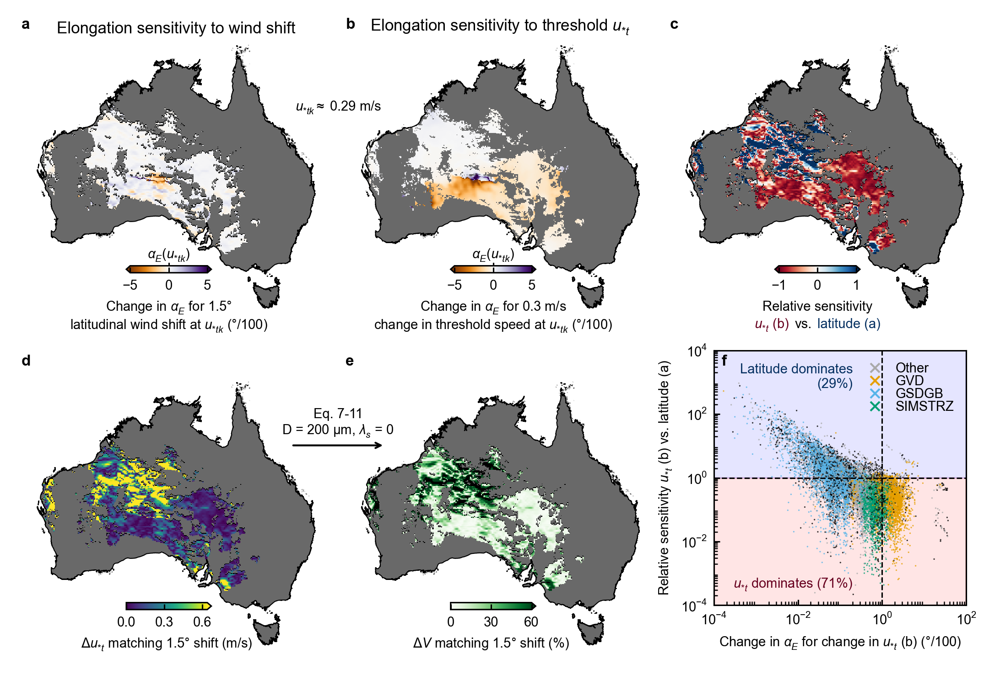

In [6]:
dl = 1.5 # latitude change
du = 0.3 # threshold friction speed
sf = 0.01 # scale factor

draft = False

### Colormap for nnan data
import matplotlib as mpl
cmap = mpl.colormaps['spring']
but0c = cmap(0.0)

### Setup figure
figw,figh = 180/25.4,120/25.4 
figa = figw/figh

### Panel label setup
labc = 'lower'
labx = (fs+1)/2/72/figw
laby = labx*figa*(2+(0 if labc=='lower' else 0.5))
labs = ['a','b','c','d','e','f','g','h','i'] 

### Scatter plot labels
labels = ['No match','Other','GVD','GSDGB','SIMSTRZ']
colors = ['black',"darkgrey","#E69F00","#56B4E9","#009E73"]
cmap = ListedColormap(colors[1:])

### Buffer definitions (could do with a clean up)
xoffl=0.05771995659722229
xoffr=0.011465277777777727
yoffb=0.06155972222222222
yofft=0.0077611111111111075
bufx = 0.01
bufy = bufx*figa

### Axis definitons (could do with a cleanup)
ax0w = (1-2*xoffr-2*bufx)/3
ax0h = ax0w*figa
ax0l,ax0b = xoffr,1-fs/2/72-ax0h
ax1l,ax1b,ax1w,ax1h = ax0l+ax0w+bufx,ax0b,ax0w,ax0h
ax2l,ax2b,ax2w,ax2h = 2/3+xoffl+0.00035277777777786845-0.005038475115740848,yoffb,1/3-xoffl-xoffr+0.005038475115740848,0.5-yoffb
ax3l,ax3b,ax3w,ax3h = xoffr,yoffb,ax0w,ax0h
testoff=1-(2/3+xoffl+0.00035277777777786845-0.005038475115740848+1/3-xoffl-xoffr+0.005038475115740848)+0.01

### PLOTTING ###
fig = plt.figure(figsize=(figw,figh)) 

### Top left panel: elongationmode sensitivity to change in latitude
ax = fig.add_axes([testoff,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.daedphi_kalma_fix*dl*sf*180/np.pi,vmin=-5,vmax=5,cmap="PuOr",rasterized=True)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
# cax.set_xlabel("$\\Delta \\phi \\times \\frac{\\partial \\alpha_{E}}{\\partial \\phi}|_{u_{*t}=u_{*t0k}} \\times sf$ (°)\n$\\Delta \\phi$ = %.2f DD, $sf$ = %.2f"%(dl,sf))
cax.set_xlabel("Change in $\\alpha_{E}$ for 1.5°\nlatitudinal wind shift at $u_{*tk}$ (°/100)")
cax.set_xticks([-5,0,5])
cax.text(0, 1.4, '$\\alpha_E(u_{*tk})$',color='k',ha='center', va='bottom',transform=cax.get_xaxis_transform())
cax.axvline(x=0, color='k', linewidth=0.75, ymin=1.1, ymax=1.4,clip_on=False)
AUS_back(ax)
ax.set_title("Elongation sensitivity to wind shift",va="top")
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Top middle panel: elongationmode sensitivity to change in ut
ax = fig.add_axes([testoff+1/3,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.daedut_kalma_fix*du*sf*180/np.pi,vmin=-5,vmax=5,cmap="PuOr",rasterized=True)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
# cax.set_xlabel("$\\Delta u_{*t} \\times \\frac{\\partial \\alpha_{E}}{\\partial u_{*t}}|_{u_{*t}=u_{*t0k}} \\times sf$ (°)\n$\\Delta u_{*t}$ = %.2f m/s, $sf$ = %.2f"%(du,sf))
cax.set_xlabel("Change in $\\alpha_{E}$ for 0.3 m/s\nchange in threshold speed at $u_{*tk}$ (°/100)")
cax.set_xticks([-5,0,5])
cax.text(0, 1.4, '$\\alpha_E(u_{*tk})$',color='k',ha='center', va='bottom',transform=cax.get_xaxis_transform())
cax.axvline(x=0, color='k', linewidth=0.75, ymin=1.1, ymax=1.4,clip_on=False)
AUS_back(ax)
ax.set_title("Elongation sensitivity to threshold $u_{*t}$",va="top")
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Top right: Ratio of changes in top left and top middle panel
ax = fig.add_axes([testoff+2/3,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,abs(ds.daedphi_kalma_fix*dl*sf*180/np.pi)/abs(ds.daedut_kalma_fix*du*sf*180/np.pi)-1,vmin=-1,vmax=1,cmap="RdBu",rasterized=True)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
# cax.set_xlabel(
#     r"$\left[|\Delta\phi\times\frac{\partial \alpha_E}{\partial \phi}|"
#     r"\middle/\Delta u_{*t}\times\frac{\partial \alpha_E}{\partial u_{*t}}|\right]|"
#     r"_{u_{*t}=u_{*t0k}}$-1"
# )
# cax.set_xlabel("Relative sensitivity\nlatitude (a) vs. $u_{*t}$ (b)")
cmap = plt.get_cmap("RdBu")
col_low = cmap(0.0)
col_high = cmap(1.0)
line1 = TextArea("Relative sensitivity",)
line2 = HPacker(
    children=[
        TextArea("$u_{*t}$ (b)", textprops=dict(color=col_low)),
        TextArea("vs."),
        TextArea("latitude (a)", textprops=dict(color=col_high)),
    ],
    align="baseline", pad=0, sep=3,
)
box = VPacker(children=[line1, line2], align="center", pad=0, sep=2)

cax.add_artist(
    AnchoredOffsetbox(
        loc="upper center", child=box, pad=0, frameon=False,
        bbox_to_anchor=(0.5, -4), bbox_transform=cax.transAxes, borderpad=0,
    )
)
cax.set_xticks([-1,0,1])
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")


## Bottom left: Change in ut required to match the influence of 1.5 DD change in latitude
du_comp = (abs(ds.daedphi_kalma_fix)*dl/abs(ds.daedut_kalma_fix)) # change in ut required to match change in latitude position
ax = fig.add_axes([testoff,0+0.0038805555555555538 -0.02,1/3-2*testoff,1/2-yofft])
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,du_comp,vmin=0,vmax=0.64,cmap="viridis",rasterized=True)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="max")
# cax.set_xlabel(r"$\Delta u_{*t_{match}} = \left.|\Delta \phi \times \frac{\partial \alpha_{E}}{\partial \phi}|_{u_{*t}=u_{*t0k}}\middle/|\frac{\partial \alpha_{E}}{\partial u_{*t}}|_{u_{*t}=u_{*t0k}}|\right.$ (m/s)",labelpad=0,loc="right")
cax.set_xlabel("$\\Delta u_{*t}$ matching 1.5° shift (m/s)")
cax.set_xticks([0,0.3,0.6])
# cax.xaxis.set_label_coords(1.7,-3)
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Bottom middle: Approximate equivalent of change in vegetation to bottom left panel
# evaluating the change in veg if we where to increase the baseline (utk) by the amount of ut match
utk = float(6.5*kappa/np.log(z/z0))
Av_base = Av_from_ut(np.array([utk]), 200e-6)
Av_new  = Av_from_ut(utk + du_comp, 200e-6)
dAv_comp = Av_new - Av_base
ax = fig.add_axes([testoff+1/3,0+0.0038805555555555538-0.02,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,dAv_comp*100,vmin=0,vmax=60,cmap="Greens",rasterized=True)
# pcm = ax.pcolormesh(ds.longitude,ds.latitude,np.where(~np.isnan(ds.ut_opt),dAv_comp*100,np.nan),vmin=0,vmax=60,cmap="Greens",rasterized=True)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="max")
cax.set_xlabel("$\\Delta V$ matching 1.5° shift (%)")
cax.set_xticks([0,30,60])
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Bottom right: Relative sensitivity of top left panel and top middle panel over top middle scatter
ax = fig.add_axes([ax2l,ax2b+0.045-0.02,ax2w-0.01,ax2h-0.045])
ax.fill_between([10**-4,10**2],1,0,color="red",zorder=0,alpha=0.1)
ax.fill_between([10**-4,10**2],1,10**4,color="blue",zorder=0,alpha=0.1)
regmask = ((~np.isnan(ds.ut_opt)&ds.GVD)*2+(~np.isnan(ds.ut_opt)&ds.GSDGB)*3+(~np.isnan(ds.ut_opt)&ds.SIMSTRZ)*4)
regmask = xr.where((~np.isnan(ds.ut_opt)&(regmask==0)),1,regmask)
regscat = pd.concat([np.abs(ds.daedut_kalma_fix*du*sf*180/np.pi).to_dataframe("dzdu"),(np.abs(ds.daedphi_kalma_fix*dl)/np.abs(ds.daedut_kalma_fix*du)).to_dataframe("dzdl_dzdu"),regmask.to_dataframe("region")],axis=1).dropna().sample(frac=1,random_state=10)
regscat["region_color"] = [colors[i] for i in regscat.region]
ax.scatter(regscat.dzdu,regscat.dzdl_dzdu,c=regscat.region_color,marker="x",s=0.1,alpha=0.75)
handles = [Line2D([0],[0],marker='x',color='none',markeredgecolor=colors[1:][i],markersize=1,label=labels[1:][i]) for i in range(len(labels[1:]))]
ax.legend(handles=handles,markerscale=5,frameon=False,loc=1,labelspacing=0)
# ax.set_xlabel("$\\Delta u_{*t} \\times \\frac{\\partial \\alpha_{E}}{\\partial u_{*t}}|_{u_{*t}=u_{*t0k}} \\times sf$ (°)")
# ax.set_ylabel(
#     r"$\left[|\Delta\phi\times\frac{\partial \alpha_E}{\partial \phi}|"
#     r"\middle/|\Delta u_{*t}\times\frac{\partial \alpha_E}{\partial u_{*t}}|\right]"
#     r"_{u_{*t}=u_{*t0k}}$",
#     va="baseline"
# )
ax.set_xlabel("Change in $\\alpha_{E}$ for change in $u_{*t}$ (b) (°/100)")
ax.set_ylabel("Relative sensitivity $u_{*t}$ (b) vs. latitude (a)")
ax.text(0.55,0.05,"$u_{*t}$ dominates (71%)",color=col_low,transform=ax.transAxes,va="bottom",ha="right")
ax.text(0.55,0.95,"Latitude dominates\n(29%)",color=col_high,transform=ax.transAxes,va="top",ha="right")
ax.axhline(1,color="k",ls="dashed")
ax.axvline(1,color="k",ls="dashed")
plt.xscale("log")
plt.yscale("log")
ax.set_xlim(10**-4,10**2)
ax.set_ylim(10**-4,10**4)
ax.set_xticks([10**-4,10**-2,1,10**2])
ax.set_yticks([10**-4,10**-2,1,10**2,10**4])

### Draft axis and panel labels
ax = fig.add_axes([0,0,1,1]) 
ax.text(1/3,1/3+0.01,"Eq. 7-11\nD = 200 μm, $\\lambda_s$ = 0",va="bottom",ha="center")
ax.annotate("",xy=(1/3+0.05, 1/3),xytext=(1/3-0.05, 1/3),arrowprops=dict(arrowstyle="->",color="k",lw=1))
ax.text(1/3, 0.85, r"$u_{*tk} \approx$ 0.29 m/s", ha="center")
ax.text(0+labx,1-laby,labs[0],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(1/3+labx,1-laby,labs[1],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(2/3+labx,1-laby,labs[2],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(0+labx,1/2-laby-0.02,labs[3],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(1/3+labx,1/2-laby-0.02,labs[4],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(2/3+xoffl+0.00035277777777786845-0.005038475115740848+labx,1/2-laby-0.02,labs[5],ha='left',va='baseline',fontsize=fs+1,fontweight='bold') # inside the scatter plot
ax.patch.set_alpha(0)
plt.xticks([])
plt.yticks([])

if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Main_4_dlat_dut_kalma.png')
    fig.savefig('paper_ready_plots/Main_4_dlat_dut_kalma.pdf')

#### Extended data: Interaction index and dune angle direction standard deviation

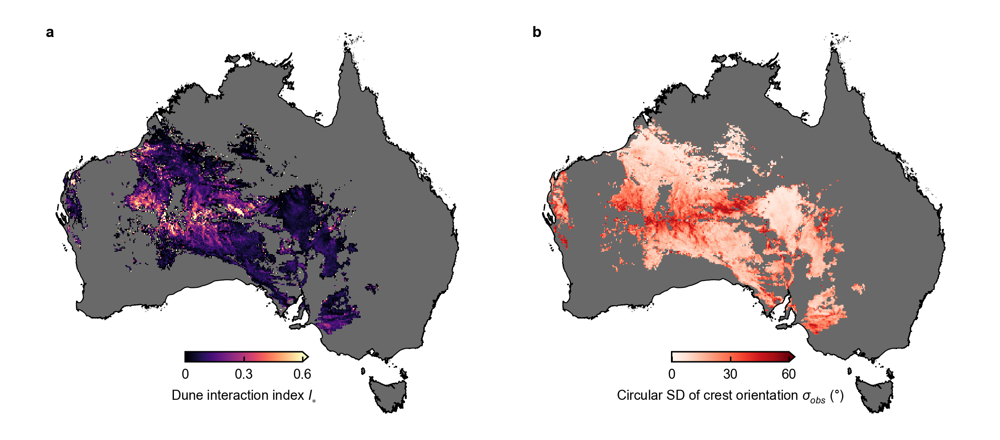

In [52]:
draft = False

### Figure and label setup
figw,figh = 180/25.4,90/((AUS_shp.bounds.maxx-AUS_shp.bounds.minx)/(AUS_shp.bounds.maxy-AUS_shp.bounds.miny))[0]/25.4 # for continent aspect ratio
figa = figw/figh 

labc = 'lower'
labx = (fs+1)/2/72/figw
laby = labx*figa*(2+(0 if labc=='lower' else 0.5))
labs = ['a','b'] 

### Left: Dune interaction index after Marvin et al. 2023
fig = plt.figure(figsize=(figw,figh)) 
ax = fig.add_axes([0.025,0+0.01,0.45,1-0.025])
AUS_shp.plot(ax=ax, facecolor='dimgray', edgecolor='none')
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.I_Marvin, cmap="magma", vmax=0.6,rasterized=True)
AUS_shp.plot(ax=ax, facecolor='none', edgecolor='black', lw=0.5)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="max")
cax.set_xticks([0,0.3,0.6])
cax.set_xticklabels([0,0.3,0.6])
cax.set_xlabel('Dune interaction index $I_{\\ast}$')
ax.axis("off")

### Right: circular standard deviation of dune crest orientation
ax = fig.add_axes([0.525,0+0.01,0.45,1-0.025])
AUS_shp.plot(ax=ax, facecolor='dimgray', edgecolor='none')
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.da_std, cmap="Reds",vmax=60*np.pi/180,rasterized=True)
AUS_shp.plot(ax=ax, facecolor='none', edgecolor='black', lw=0.5)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="max")
cax.set_xticks([0,30*np.pi/180,60*np.pi/180])
cax.set_xticklabels([0,30,60])
cax.set_xlabel('Circular SD of crest orientation $\\sigma_{obs}$ (°)')
ax.axis("off")

### Draft axis and labels
ax = fig.add_axes([0,0,1,1]) 
ax.patch.set_alpha(0)
ax.text(0.025+labx,1-laby-0.02,labs[0],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(0.525+labx,1-laby-0.02,labs[1],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')

if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Extended_1_interaction_std.png')
    fig.savefig('paper_ready_plots/Extended_1_interaction_std.pdf')
plt.show()

#### Extended data: Maximum threshold speed, equivalent max vegetation and difference between shutdown vegetation and modern minimum vegetation

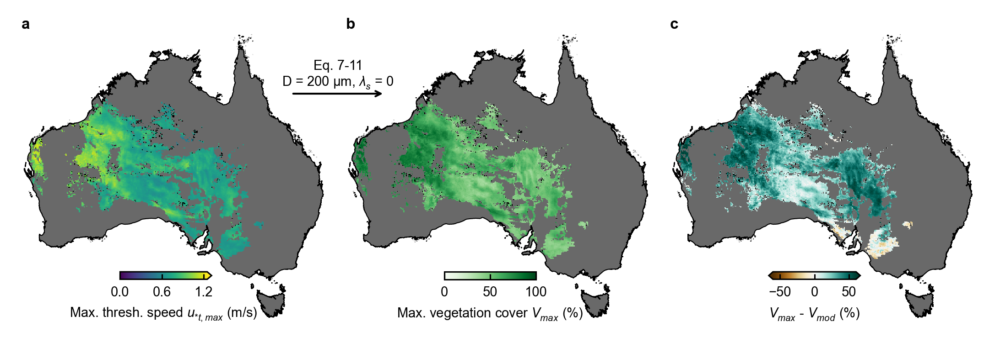

In [10]:
draft = False

### Figure and label setup
figw,figh = 180/25.4,70/((AUS_shp.bounds.maxx-AUS_shp.bounds.minx)/(AUS_shp.bounds.maxy-AUS_shp.bounds.miny))[0]/25.4 # for continent aspect ratio
figa = figw/figh

labc = 'lower'
labx = (fs+1)/2/72/figw
laby = labx*figa*(2+(0 if labc=='lower' else 0.5))
labs = ['a','b','c'] 

### PLOTTING ###
fig = plt.figure(figsize=(figw,figh))

### Left panel: Maximum threshold speed plot
ax = fig.add_axes([0.0075,0+0.01,1/3-0.01*2,1-0.025])
ax.pcolormesh(ds.longitude,ds.latitude,ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.ut_max,cmap="viridis",vmin=0, vmax=1.25,rasterized=True)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="max")
cbar.ax.set_xticks([0,0.6,1.2])
cbar.ax.set_xlabel("Max. thresh. speed $u_{*t,max}$ (m/s)")
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Middle panel: Maximum threoretical vegetation cover before flux shutdown
ax = fig.add_axes([1/3+0.0075,0+0.01,1/3-0.01*2,1-0.025])
ax.pcolormesh(ds.longitude,ds.latitude,ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,Av_from_ut(ds.ut_max,200e-6)*100,cmap="Greens",vmin=0,vmax=100,rasterized=True)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05)
cbar.ax.set_xticks([0,50,100])
cbar.ax.set_xlabel('Max. vegetation cover $V_{max}$ (%)')
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Right panel: Difference between maximum vegetation cover (middle panel) and minimum modern vegetation cover
ax = fig.add_axes([2/3+0.0075,0+0.01,1/3-0.01*2,1-0.025])
ax.pcolormesh(ds.longitude,ds.latitude,ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,Av_from_ut(ds.ut_max,200e-6)*100-ds.tot_cov.min("time"),cmap="BrBG",vmin=-60,vmax=60,rasterized=True)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
cbar.ax.set_xlabel("$V_{max}$ - $V_{mod}$ (%)")
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Draft axis and labels
ax = fig.add_axes([0,0,1,1])
ax.text(1/3,3/4+0.01,"Eq. 7-11\nD = 200 μm, $\\lambda_s$ = 0",va="bottom",ha="center")
ax.annotate("",xy=(1/3+0.05, 3/4),xytext=(1/3-0.05, 3/4),arrowprops=dict(arrowstyle="->",color="k",lw=1))
ax.patch.set_alpha(0)
plt.xticks([])
plt.yticks([])
ax.text(0+labx,1-laby,labs[0],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(1/3+labx,1-laby,labs[1],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(2/3+labx,1-laby,labs[2],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')

if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Extended_2_ut_max.png')
    fig.savefig('paper_ready_plots/Extended_2_ut_max.pdf')
plt.show()

#### Extended data: Vegetation per region

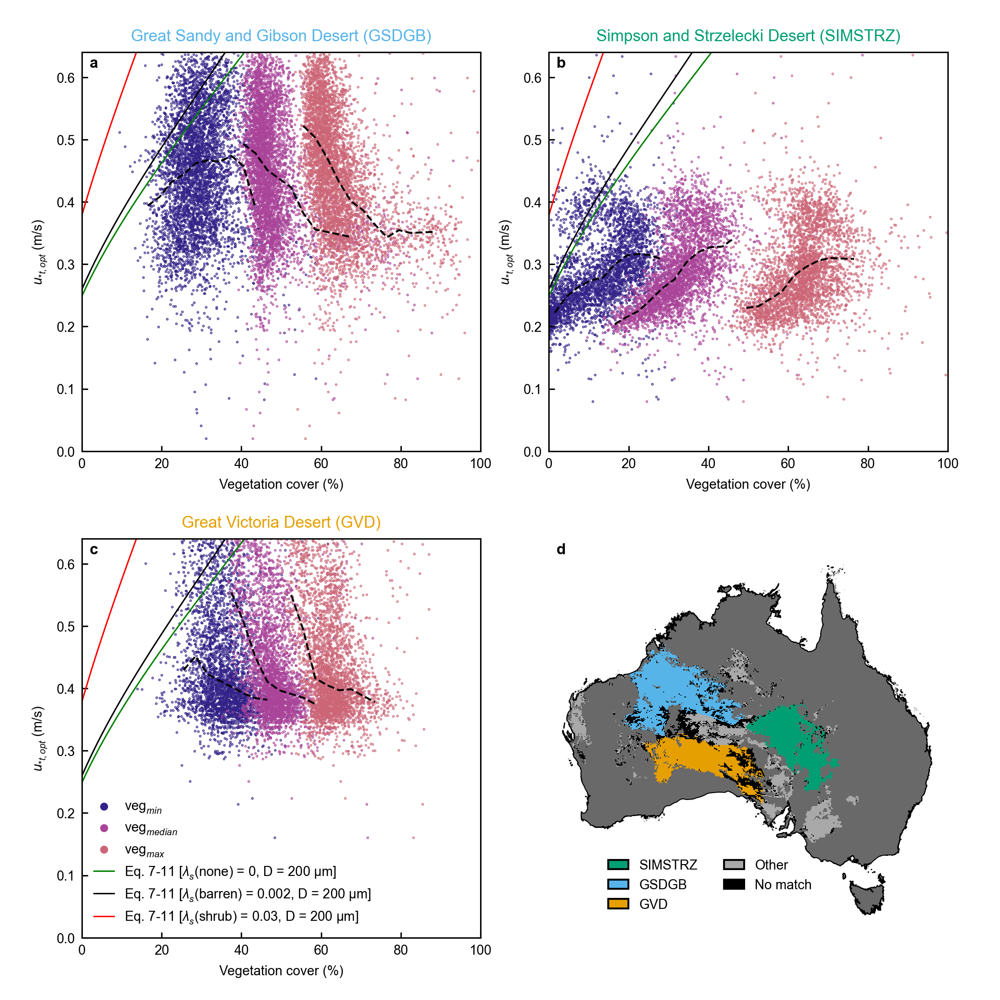

In [11]:
draft = False

### Figure and label setup
figw,figh = 180/25.4,180/25.4 
figa = figw/figh 
bufx = 0.1
bufy = bufx*figa
AUSa = ((AUS_shp.bounds.maxx-AUS_shp.bounds.minx)/(AUS_shp.bounds.maxy-AUS_shp.bounds.miny))[0]
labc = 'lower'
labx = (fs+1)/2/72/figw
laby = labx*figa*(2+(0 if labc=='lower' else 0.5))
labs = ['a','b','c','d'] 

### Definitions for scatter plots
labels = ['No match','Other','GVD','GSDGB','SIMSTRZ']
colors = ['black',"darkgrey","#E69F00","#56B4E9","#009E73"]
min_col = "#332288"   # dark indigo
med_col = "#AA4499"   # purple
max_col = "#CC6677"   # rose
cmap = ListedColormap(colors[1:])

### Tick params
tparam = dict(axis='both', which='both',length=0,labelbottom=False,labelleft=False,bottom=False,left=False,top=False,right=False)

### Axes definitions
ax0w = (1-bufx*3)/2
ax0h = ax0w*figa
ax0l,ax0b = bufx,2*bufy+ax0h
ax1l,ax1b,ax1w,ax1h = ax0l+ax0w+bufx,ax0b,ax0w,ax0h
ax2l,ax2b,ax2w,ax2h = ax0l,ax0b-ax0h-bufy,ax0w,ax0h
ax3l,ax3b,ax3w,ax3h = ax0l+ax0w+bufx/2-0.0025,ax0b-ax0h-bufy,ax0h*AUSa,ax0h

### PLOTTING ###
fig = plt.figure(figsize=(figw,figh)) 

### Top left panel: Great Sandy Desert and Gibson Desert vegetation cover and threshold speed 
ax = fig.add_axes([ax0l-0.03,ax0b,ax0w+0.06,ax0h+0.06*figa])
tempmask = (~np.isnan(ds.ut_opt.values))&ds.GSDGB
ax.scatter(ds.tot_cov.min("time").where(tempmask),ds.ut_opt.where(tempmask),s=0.1,color=min_col)
ax.scatter(ds.tot_cov.median("time").where(tempmask),ds.ut_opt.where(tempmask),s=0.1,facecolor=med_col)
ax.scatter(ds.tot_cov.max("time").where(tempmask),ds.ut_opt.where(tempmask),s=0.1,facecolor=max_col)
tbin,telon,tq25,tq75 = bin_veg_ut(ds.ut_opt.where(tempmask).values.flatten(),ds.tot_cov.where(tempmask).min("time").values.flatten(),n_points=50)
ax.plot(tbin,telon,color="k",ls="dashed",lw=1)
tbin,telon,tq25,tq75 = bin_veg_ut(ds.ut_opt.where(tempmask).values.flatten(),ds.tot_cov.where(tempmask).median("time").values.flatten(),n_points=50)
ax.plot(tbin,telon,color="k",ls="dashed",lw=1)
tbin,telon,tq25,tq75 = bin_veg_ut(ds.ut_opt.where(tempmask).values.flatten(),ds.tot_cov.where(tempmask).max("time").values.flatten(),n_points=50)
ax.plot(tbin,telon,color="k",ls="dashed",lw=1)
ax.plot(np.linspace(0,1,100)*100,ut(ut0(200e-6),fr(np.linspace(0,1,100),0.002)),color="k")
ax.plot(np.linspace(0,1,100)*100,ut(ut0(200e-6),fr(np.linspace(0,1,100),0.03)),color="red")
ax.plot(np.linspace(0,1,100)*100,ut(ut0(200e-6),fr(np.linspace(0,1,100),0)),color="green")
ax.set_xlim(0,100)
ax.set_ylim(0,0.64)
ax.set_xlabel('Vegetation cover (%)')
ax.set_ylabel('$u_{*t,opt}$ (m/s)')
ax.set_title("Great Sandy and Gibson Desert (GSDGB)", color=colors[3])

### Top right panel: Simpson and Strzelecki Desert vegetation cover and threshold speed
ax = fig.add_axes([ax1l,ax1b,ax1w+0.06,ax1h+0.06*figa])
tempmask = (~np.isnan(ds.ut_opt.values))&ds.SIMSTRZ
ax.scatter(ds.tot_cov.min("time").where(tempmask),ds.ut_opt.where(tempmask),s=0.1,color=min_col)
ax.scatter(ds.tot_cov.median("time").where(tempmask),ds.ut_opt.where(tempmask),s=0.1,facecolor=med_col)
ax.scatter(ds.tot_cov.max("time").where(tempmask),ds.ut_opt.where(tempmask),s=0.1,facecolor=max_col)
tbin,telon,tq25,tq75 = bin_veg_ut(ds.ut_opt.where(tempmask).values.flatten(),ds.tot_cov.where(tempmask).min("time").values.flatten(),n_points=50)
ax.plot(tbin,telon,color="k",ls="dashed",lw=1)
tbin,telon,tq25,tq75 = bin_veg_ut(ds.ut_opt.where(tempmask).values.flatten(),ds.tot_cov.where(tempmask).median("time").values.flatten(),n_points=50)
ax.plot(tbin,telon,color="k",ls="dashed",lw=1)
tbin,telon,tq25,tq75 = bin_veg_ut(ds.ut_opt.where(tempmask).values.flatten(),ds.tot_cov.where(tempmask).max("time").values.flatten(),n_points=50)
ax.plot(tbin,telon,color="k",ls="dashed",lw=1)
ax.plot(np.linspace(0,1,100)*100,ut(ut0(200e-6),fr(np.linspace(0,1,100),0.002)),color="k")
ax.plot(np.linspace(0,1,100)*100,ut(ut0(200e-6),fr(np.linspace(0,1,100),0.03)),color="red")
ax.plot(np.linspace(0,1,100)*100,ut(ut0(200e-6),fr(np.linspace(0,1,100),0)),color="green")
ax.set_xlim(0,100)
ax.set_ylim(0,0.64)
ax.set_xlabel('Vegetation cover (%)')
ax.set_ylabel('$u_{*t,opt}$ (m/s)')
ax.set_title("Simpson and Strzelecki Desert (SIMSTRZ)", color=colors[4])

### Bottom left panel: Great Victoria Desert vegetation cover and threshold speed
ax = fig.add_axes([ax2l-0.03,ax2b-0.05*figa,ax2w+0.06,ax2h+0.06*figa])
tempmask = (~np.isnan(ds.ut_opt.values))&ds.GVD
ax.scatter(ds.tot_cov.min("time").where(tempmask),ds.ut_opt.where(tempmask),s=0.1,color=min_col,label="veg$_{min}$")
ax.scatter(ds.tot_cov.median("time").where(tempmask),ds.ut_opt.where(tempmask),s=0.1,facecolor=med_col,label="veg$_{median}$")
ax.scatter(ds.tot_cov.max("time").where(tempmask),ds.ut_opt.where(tempmask),s=0.1,facecolor=max_col,label="veg$_{max}$")
tbin,telon,tq25,tq75 = bin_veg_ut(ds.ut_opt.where(tempmask).values.flatten(),ds.tot_cov.where(tempmask).min("time").values.flatten(),n_points=50)
ax.plot(tbin,telon,color="k",ls="dashed",lw=1)
tbin,telon,tq25,tq75 = bin_veg_ut(ds.ut_opt.where(tempmask).values.flatten(),ds.tot_cov.where(tempmask).median("time").values.flatten(),n_points=50)
ax.plot(tbin,telon,color="k",ls="dashed",lw=1)
tbin,telon,tq25,tq75 = bin_veg_ut(ds.ut_opt.where(tempmask).values.flatten(),ds.tot_cov.where(tempmask).max("time").values.flatten(),n_points=50)
ax.plot(tbin,telon,color="k",ls="dashed",lw=1)
ax.plot(np.linspace(0,1,100)*100,ut(ut0(200e-6),fr(np.linspace(0,1,100),0)),color="green",label="Eq. 7-11 [$\\lambda_{s}$(none) = 0, D = 200 µm]")
ax.plot(np.linspace(0,1,100)*100,ut(ut0(200e-6),fr(np.linspace(0,1,100),0.002)),color="k" ,label="Eq. 7-11 [$\\lambda_{s}$(barren) = 0.002, D = 200 µm]")
ax.plot(np.linspace(0,1,100)*100,ut(ut0(200e-6),fr(np.linspace(0,1,100),0.03)),color="red",label="Eq. 7-11 [$\\lambda_{s}$(shrub) = 0.03, D = 200 µm]")
ax.set_xlim(0,100)
ax.set_ylim(0,0.64)
ax.set_xlabel('Vegetation cover (%)')
ax.set_ylabel('$u_{*t,opt}$ (m/s)')
ax.set_title("Great Victoria Desert (GVD)", color=colors[2])
ax.legend(markerscale=10,frameon=False,loc=3)

### Bottom right panel: Overview of the dunefields
ax = fig.add_axes([ax3l+0.035,ax3b-0.035*figa,ax3w+0.03,ax3h+0.03*figa])
AUS_shp.plot(ax=ax, facecolor='dimgray', edgecolor='none')
ax.pcolormesh(ds.longitude,ds.latitude,ds.dune_mask.where(ds.dune_mask),cmap="Greys_r",rasterized=True)
ax.pcolormesh(ds.longitude,ds.latitude,(ds.dune_mask.where(ds.dune_mask)*0+ds.GVD*1+ds.GSDGB*2+ds.SIMSTRZ*3).where(~np.isnan(ds.ut_opt)),cmap=cmap, vmin=-0.5, vmax=3.5,rasterized=True)
AUS_shp.plot(ax=ax, facecolor='none', edgecolor='black', lw=0.5)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
handles = [mpatches.Patch(facecolor=colors[i],edgecolor="k", label=labels[i]) for i in range(len(labels))]
ax.legend(handles=handles[::-1],loc='lower left',bbox_to_anchor=(0.1,0), ncols=2,frameon=False,facecolor='white',edgecolor='none')
ax.axis("off")

### Draft axis
ax = fig.add_axes([0,0,1,1]) 
ax.patch.set_alpha(0)
plt.xticks([])
plt.yticks([])

### Labels
for i,pan in enumerate(fig.axes[:-2]):
    axl,axb,axh = np.array(pan.get_position().bounds)[[0,1,3]]
    if i==1:
        axt3l = axl
    elif i==2:
        axt3b = axb
    ax.text(axl+labx,axb+axh-laby,labs[i],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(axt3l+labx,axt3b+axh-laby,labs[3],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')

if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Extended_3_vegetation_per_region.png')
    fig.savefig('paper_ready_plots/Extended_3_vegetation_per_region.pdf')
plt.show()

#### Extended data: Scatter of modern minimum threshold speed against observed slope asymmetry

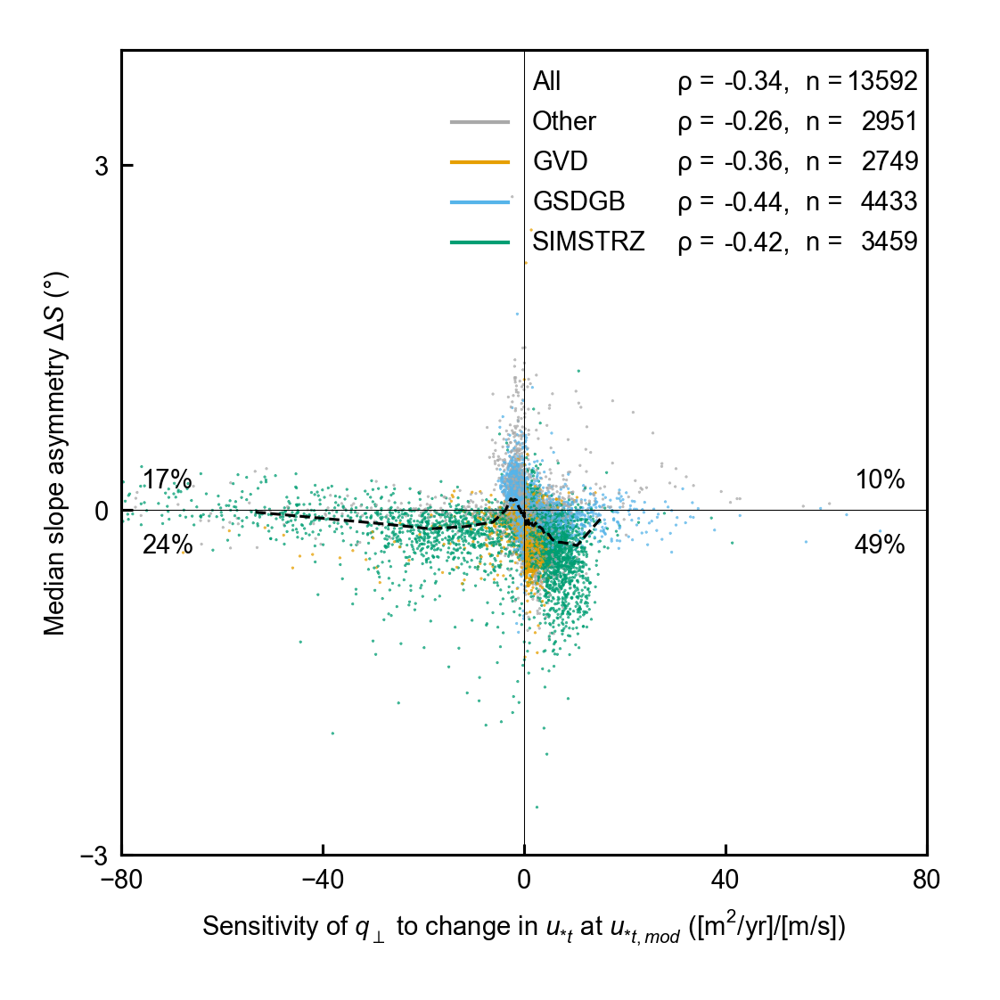

In [107]:
draft = False

### Setup figure
figw,figh = 90/25.4,90/25.4 # for continent aspect ratio
figa = figw/figh

### Plotting
fig = plt.figure(figsize=(figw,figh)) 
ax = fig.add_axes([0.1,0.125,0.85,0.85])
regmask = ((~np.isnan(ds.ut_opt)&ds.GVD)*2+(~np.isnan(ds.ut_opt)&ds.GSDGB)*3+(~np.isnan(ds.ut_opt)&ds.SIMSTRZ)*4)
regmask = xr.where((~np.isnan(ds.ut_opt)&(regmask==0)),1,regmask)
regscat = pd.concat([ds.lmrs.to_dataframe(),ds.dqncedut_mod.where(regmask>0).to_dataframe(),regmask.to_dataframe("region")],axis=1).dropna().sample(frac=1,random_state=10)
regscat["region_color"] = [colors[i] for i in regscat.region]
regscat["region_label"] = [labels[i] for i in regscat.region]
regscat_sorted = regscat[["dqncedut_mod", "lmrs"]].dropna().sort_values("dqncedut_mod")
regscat_sorted["dqncedut_mod"] = regscat_sorted["dqncedut_mod"]*s2y
regscat_sorted["bin"] = pd.qcut(regscat_sorted["dqncedut_mod"], q=50)
g = regscat_sorted.groupby("bin", observed=True).agg(x=("dqncedut_mod", "median"),mean=("lmrs", "mean"),median=("lmrs", "median"))

rho_all, _ = stats.spearmanr(regscat.dqncedut_mod, regscat.lmrs)
rows = [("All", rho_all, len(regscat), None)]
for i in range(1, len(labels)):
    gtemp = regscat[regscat.region == i]
    rho, _ = stats.spearmanr(gtemp.dqncedut_mod, gtemp.lmrs)
    rows.append((labels[i], rho, len(gtemp), colors[i]))
ax.scatter(regscat.dqncedut_mod*s2y,regscat.lmrs,c=regscat.region_color,marker="x",s=0.1,alpha=0.75)
ax.plot(g["x"], g["median"], c="k", ls="dashed")
handles = [Line2D([0],[0],marker='x',color='none',markeredgecolor=colors[1:][i],markersize=1,label=labels[1:][i]) for i in range(len(labels[1:]))]

# column positions in axes coordinates (tweak to taste)
x_line = (0.41, 0.48)   # line sample start/end
x_name = 0.51          # region name, left-aligned
x_rholab, x_rho = 0.69, 0.83   # "ρ=" left-aligned, value right-aligned
x_nlab, x_n = 0.85, 0.99       # "n=" left-aligned, count right-aligned
y0, dy = 0.96, 0.05

for k, (name, rho, n, c) in enumerate(rows):
    y = y0 - k*dy
    kw = dict(transform=ax.transAxes, va="center", zorder=5)
    if c is not None:
        ax.plot(x_line, [y, y], color=c, lw=1, transform=ax.transAxes,
                clip_on=False, zorder=5)
    ax.text(x_name,   y, name,          ha="left",  **kw)
    ax.text(x_rholab, y, "ρ = ",          ha="left",  **kw)
    ax.text(x_rho,    y, f"{rho:.2f},",  ha="right", **kw)
    ax.text(x_nlab,   y, "n = ",          ha="left",  **kw)
    ax.text(x_n,      y, f"{n}",        ha="right", **kw)
    
ax.axvline(0,color="k",lw=0.25)
ax.axhline(0,color="k",lw=0.25)
ax.set_ylabel('Median slope asymmetry $\\Delta S$ ($°$)',va="baseline")
ax.set_xlabel('Sensitivity of $q_{\\perp}$ to change in $u_{*t}$ at $u_{*t,mod}$ ([m$^2$/yr]/[m/s])')
# ax.text(0.95,0.95,r'$\frac{\partial q_{\perp}(\alpha_{obs})}{\partial u_{*t}}|_{u_{*t}=u_{*t,mod}}$',transform=ax.transAxes,ha="right",va="top")
# ax.set_xlabel(r'$\left.\partial\langle q_{s,c_\perp}(\alpha_{obs}) \rangle \middle/ \partial u_{*t}\right.|_{u_{*t}=u_{*t_{min,200µm}}}$ ([m$^2$/yr]/[m/s])')
ax.set_xlim(-80,80)
ax.set_ylim(-3,4)
ax.set_yticks([-3,0,3])
ax.set_xticks([-80,-40,0,40,80])

# For percentages
all_NN = round(((regscat.dqncedut_mod<0)&(regscat.lmrs<0)).sum()/len(regscat)*100,0).astype(int)
all_PN = round(((regscat.dqncedut_mod>0)&(regscat.lmrs<0)).sum()/len(regscat)*100,0).astype(int)
all_NP = round(((regscat.dqncedut_mod<0)&(regscat.lmrs>0)).sum()/len(regscat)*100,0).astype(int)
all_PP = round(((regscat.dqncedut_mod>0)&(regscat.lmrs>0)).sum()/len(regscat)*100,0).astype(int)
ax.text(0.025,0.4,f"{all_NN}%",ha="left",va="top",transform=ax.transAxes)
ax.text(0.025,0.45,f"{all_NP}%",ha="left",va="bottom",transform=ax.transAxes)
ax.text(0.975,0.4,f"{all_PN}%",ha="right",va="top",transform=ax.transAxes)
ax.text(0.975,0.45,f"{all_PP}%",ha="right",va="bottom",transform=ax.transAxes)

### Draft axis
ax = fig.add_axes([0,0,1,1]) 
ax.patch.set_alpha(0)

if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Extended_4_slope_versus_modern.png')
    fig.savefig('paper_ready_plots/Extended_4_slope_versus_modern.pdf')

#### Extended data: RDP/DP bare

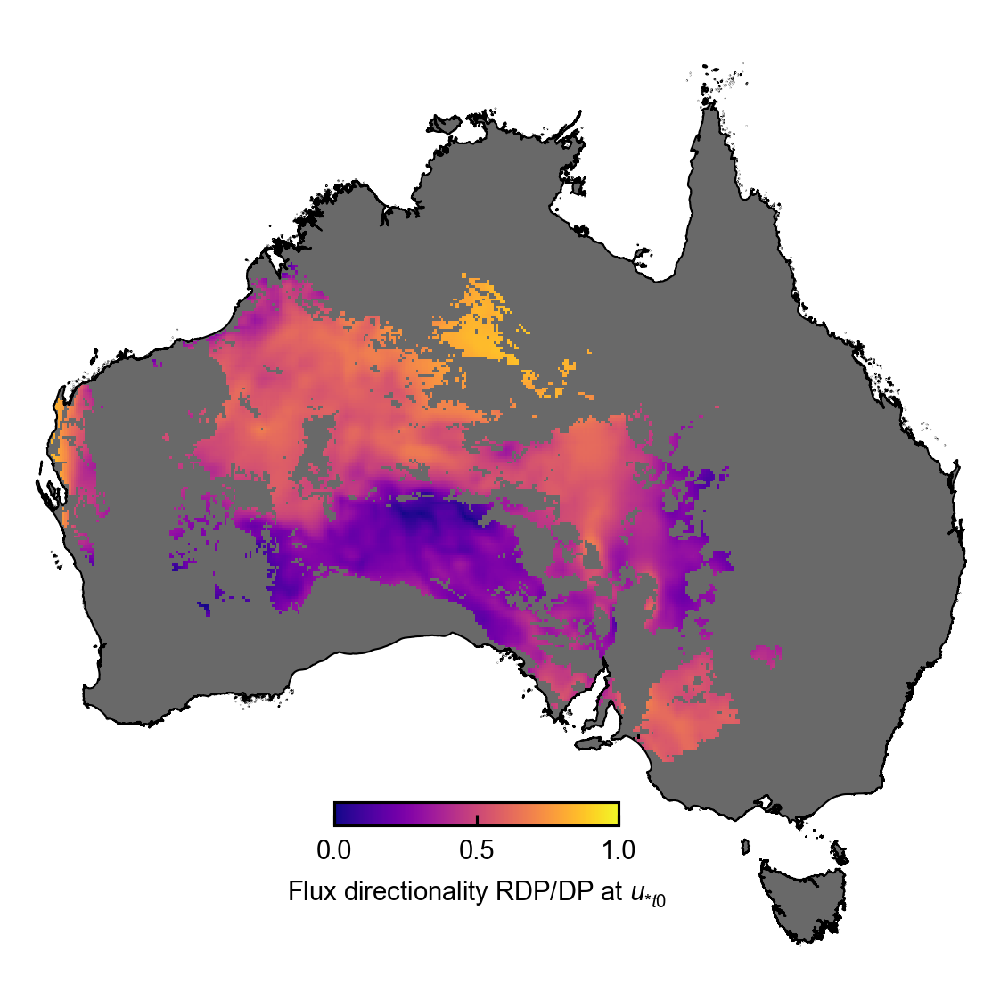

In [14]:
draft = False

### Setup figure
figw,figh = 90/25.4,90/25.4 # for continent aspect ratio
figa = figw/figh

### Plotting
uinter = float(ut0(200e-6))
# rdp_dp = (ds.rdpm/ds.dpm).interp(ut=uinter)
fig = plt.figure(figsize=(figw,figh)) 
ax = fig.add_axes([0,0,1,1])
AUS_shp.plot(ax=ax, facecolor='dimgray', edgecolor='none')
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,ds.qha_rdp_dp.interp(ut=uinter).where(ds.dune_mask), cmap="plasma", vmin=0, vmax=1,rasterized=True)
# pcm = ax.pcolormesh(ds.longitude,ds.latitude,rdp_dp.where(ds.dune_mask), cmap="plasma", vmin=0, vmax=1,rasterized=True)
AUS_shp.plot(ax=ax, facecolor='none', edgecolor='black', lw=0.5)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05)
cbar.ax.set_xticks([0,0.5,1])
# cbar.ax.set_xlabel('Flux directionality RDP/DP$|_{u_{*t}=u_{*t0}}$')
cbar.ax.set_xlabel('Flux directionality RDP/DP at $u_{*t0}$')
ax.axis("off")

### Draft axis
ax = fig.add_axes([0,0,1,1]) 
ax.patch.set_alpha(0)

if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Extended_6_rdp_dp_ut0.png')
    fig.savefig('paper_ready_plots/Extended_6_rdp_dp_ut0.pdf')

#### Extended data: Sigmas at utopt

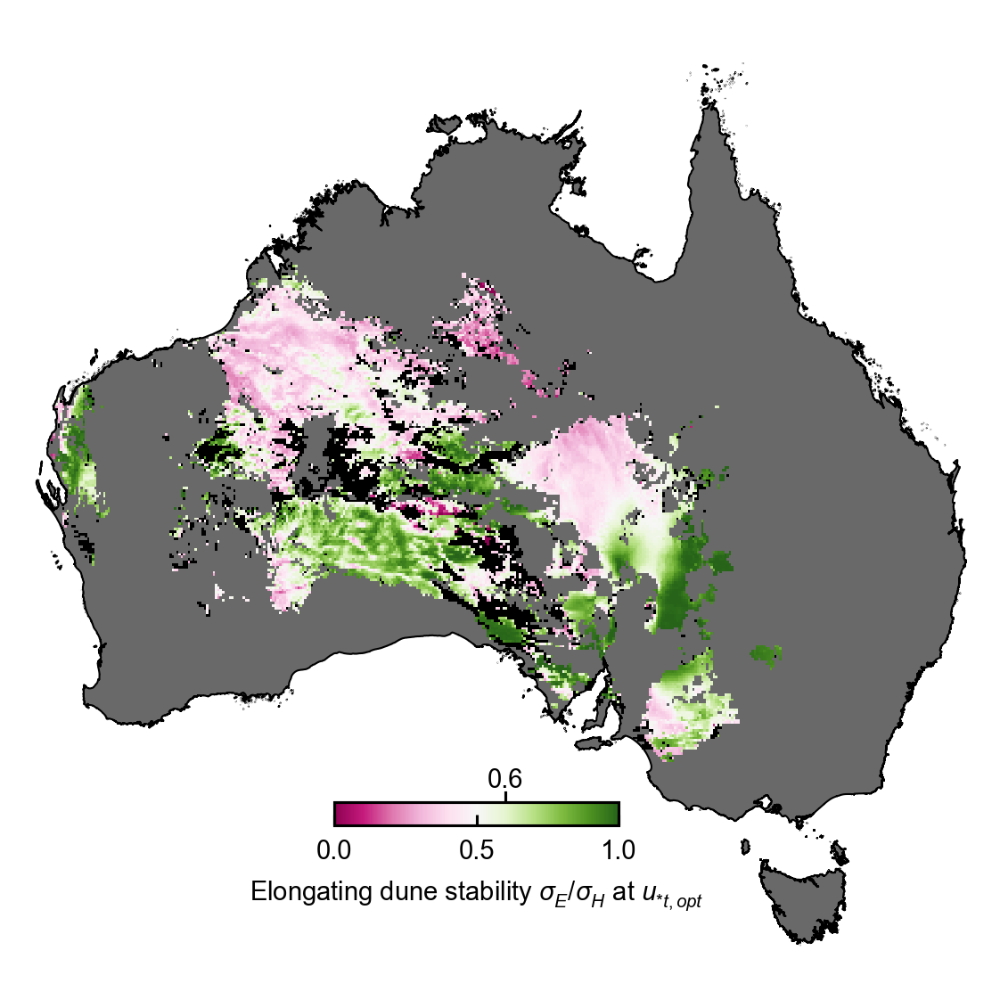

In [14]:
draft = False

### Setup figure
figw,figh = 90/25.4,90/25.4 # for continent aspect ratio
figa = figw/figh

### Plotting
sige_sigh_opt = xr.apply_ufunc(interp_cell, ds.sige_sigh, ds.ut_opt,kwargs={"ut": ds.ut.values},input_core_dims=[["ut"], []],vectorize=True, output_dtypes=[float])
fig = plt.figure(figsize=(figw,figh)) 
ax = fig.add_axes([0,0,1,1])
AUS_shp.plot(ax=ax, facecolor='dimgray', edgecolor='none')
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r",rasterized=True)
pcm = ax.pcolormesh(ds.longitude,ds.latitude,sige_sigh_opt,cmap="PiYG",vmin=0,vmax=1,rasterized=True)
AUS_shp.plot(ax=ax, facecolor='none', edgecolor='black', lw=0.5)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
cax = ax.inset_axes([0.325, 0.15, 0.3, 0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal')
cax.axvline(x=0.6, color='k', linewidth=0.75, ymin=1.1, ymax=1.4,clip_on=False)
cax.text(0.6, 1.4, '0.6',color='k',ha='center', va='bottom',transform=cax.get_xaxis_transform())
cax.set_xticks([0, 0.5, 1])
cax.set_xlabel('Elongating dune stability $\\sigma_E/\\sigma_H$ at $u_{*t,opt}$')
ax.axis("off")

### Draft axis
ax = fig.add_axes([0,0,1,1]) 
ax.patch.set_alpha(0)

if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Extended_7_sigmas_ut_opt.png')
    fig.savefig('paper_ready_plots/Extended_7_sigmas_ut_opt.pdf')

#### FORMER: Main Figure 4 For dynamic dm

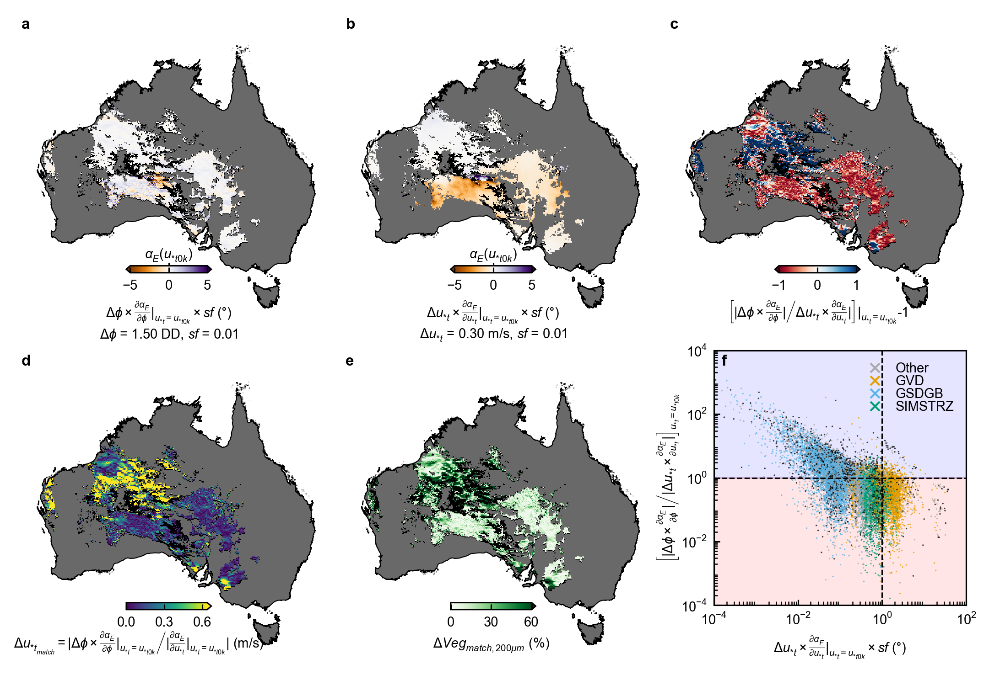

In [53]:
dl = 1.5 # latitude change
du = 0.3 # threshold friction velocity
sf = 0.01 # scale factor

draft = True

### Colormap for nnan data
import matplotlib as mpl
cmap = mpl.colormaps['spring']
but0c = cmap(0.0)

### Setup figure
figw,figh = 180/25.4,120/25.4 
figa = figw/figh

### Panel label setup
labc = 'lower'
labx = (fs+1)/2/72/figw
laby = labx*figa*(2+(0 if labc=='lower' else 0.5))
labs = ['a','b','c','d','e','f','g','h','i'] 

### Scatter plot labels
labels = ['No match','Other','GVD','GSDGB','SIMSTRZ']
colors = ['black',"darkgrey","#E69F00","#56B4E9","#009E73"]
cmap = ListedColormap(colors[1:])

### Buffer definitions (could do with a clean up)
xoffl=0.05771995659722229
xoffr=0.011465277777777727
yoffb=0.06155972222222222
yofft=0.0077611111111111075
bufx = 0.01
bufy = bufx*figa

### Axis definitons (could do with a cleanup)
ax0w = (1-2*xoffr-2*bufx)/3
ax0h = ax0w*figa
ax0l,ax0b = xoffr,1-fs/2/72-ax0h
ax1l,ax1b,ax1w,ax1h = ax0l+ax0w+bufx,ax0b,ax0w,ax0h
ax2l,ax2b,ax2w,ax2h = 2/3+xoffl+0.00035277777777786845-0.005038475115740848,yoffb,1/3-xoffl-xoffr+0.005038475115740848,0.5-yoffb
ax3l,ax3b,ax3w,ax3h = xoffr,yoffb,ax0w,ax0h
testoff=1-(2/3+xoffl+0.00035277777777786845-0.005038475115740848+1/3-xoffl-xoffr+0.005038475115740848)+0.01

### PLOTTING ###
fig = plt.figure(figsize=(figw,figh)) 

### Top left panel: elongationmode sensitivity to change in latitude
ax = fig.add_axes([testoff,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r")
pcm = ax.pcolormesh(ds.longitude,ds.latitude,(ds.daedphi_kalma*dl*sf*180/np.pi).where(~np.isnan(ds.ut_opt)),vmin=-5,vmax=5,cmap="PuOr")
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
cax.set_xlabel("$\\Delta \\phi \\times \\frac{\\partial \\alpha_{E}}{\\partial \\phi}|_{u_{*t}=u_{*t0k}} \\times sf$ (°)\n$\\Delta \\phi$ = %.2f DD, $sf$ = %.2f"%(dl,sf))
cax.set_xticks([-5,0,5])
cax.text(0, 1.4, '$\\alpha_E(u_{*t0k})$',color='k',ha='center', va='bottom',transform=cax.get_xaxis_transform())
cax.axvline(x=0, color='k', linewidth=0.75, ymin=1.1, ymax=1.4,clip_on=False)
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Top middle panel: elongationmode sensitivity to change in ut
ax = fig.add_axes([testoff+1/3,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r")
pcm = ax.pcolormesh(ds.longitude,ds.latitude,(ds.daedut_kalma*du*sf*180/np.pi).where(~np.isnan(ds.ut_opt)),vmin=-5,vmax=5,cmap="PuOr")
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
cax.set_xlabel("$\\Delta u_{*t} \\times \\frac{\\partial \\alpha_{E}}{\\partial u_{*t}}|_{u_{*t}=u_{*t0k}} \\times sf$ (°)\n$\\Delta u_{*t}$ = %.2f m/s, $sf$ = %.2f"%(du,sf))
cax.set_xticks([-5,0,5])
cax.text(0, 1.4, '$\\alpha_E(u_{*t0k})$',color='k',ha='center', va='bottom',transform=cax.get_xaxis_transform())
cax.axvline(x=0, color='k', linewidth=0.75, ymin=1.1, ymax=1.4,clip_on=False)
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Top right: Ratio of changes in top left and top middle panel
ax = fig.add_axes([testoff+2/3,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r")
pcm = ax.pcolormesh(ds.longitude,ds.latitude,(abs(ds.daedphi_kalma*dl*sf*180/np.pi)/abs(ds.daedut_kalma*du*sf*180/np.pi)-1).where(~np.isnan(ds.ut_opt)),vmin=-1,vmax=1,cmap="RdBu")
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
cax.set_xlabel(
    r"$\left[|\Delta\phi\times\frac{\partial \alpha_E}{\partial \phi}|"
    r"\middle/\Delta u_{*t}\times\frac{\partial \alpha_E}{\partial u_{*t}}|\right]|"
    r"_{u_{*t}=u_{*t0k}}$-1"
)
cax.set_xticks([-1,0,1])
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Bottom left: Change in ut required to match the influence of 1.5 DD change in latitude
du_comp = (abs(ds.daedphi_kalma)*dl/abs(ds.daedut_kalma)) # change in ut required to match change in latitude position
ax = fig.add_axes([testoff,0+0.0038805555555555538 -0.02,1/3-2*testoff,1/2-yofft])
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r")
pcm = ax.pcolormesh(ds.longitude,ds.latitude,du_comp.where(~np.isnan(ds.ut_opt)),vmin=0,vmax=0.64,cmap="viridis")
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="max")
cax.set_xlabel(r"$\Delta u_{*t_{match}} = \left.|\Delta \phi \times \frac{\partial \alpha_{E}}{\partial \phi}|_{u_{*t}=u_{*t0k}}\middle/|\frac{\partial \alpha_{E}}{\partial u_{*t}}|_{u_{*t}=u_{*t0k}}|\right.$ (m/s)",labelpad=0,loc="right")
cax.set_xticks([0,0.3,0.6])
cax.xaxis.set_label_coords(1.7,-3)
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Bottom middle: Approximate equivalent of change in vegetation to bottom left panel
# evaluating the change in veg if we where to increase the baseline (utk) by the amount of ut match
utk = float(6.5*kappa/np.log(z/z0))
Av_base = Av_from_ut(np.array([utk]), 200e-6)
Av_new  = Av_from_ut(utk + du_comp, 200e-6)
dAv_comp = Av_new - Av_base
ax = fig.add_axes([testoff+1/3,0+0.0038805555555555538-0.02,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r")
pcm = ax.pcolormesh(ds.longitude,ds.latitude,np.where(~np.isnan(ds.ut_opt),dAv_comp*100,np.nan),vmin=0,vmax=60,cmap="Greens")
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="max")
cax.set_xlabel("$\\Delta Veg{_{match,200\\mu m}}$ (%)")
cax.set_xticks([0,30,60])
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Bottom right: Relative sensitivity of top left panel and top middle panel over top middle scatter
ax = fig.add_axes([ax2l,ax2b+0.045-0.02,ax2w-0.01,ax2h-0.045])
ax.fill_between([10**-4,10**2],1,0,color="red",zorder=0,alpha=0.1)
ax.fill_between([10**-4,10**2],1,10**4,color="blue",zorder=0,alpha=0.1)
regmask = ((~np.isnan(ds.ut_opt)&ds.GVD)*2+(~np.isnan(ds.ut_opt)&ds.GSDGB)*3+(~np.isnan(ds.ut_opt)&ds.SIMSTRZ)*4)
regmask = xr.where((~np.isnan(ds.ut_opt)&(regmask==0)),1,regmask)
regscat = pd.concat([np.abs(ds.daedut_kalma*du*sf*180/np.pi).to_dataframe("dzdu"),(np.abs(ds.daedphi_kalma*dl*sf*180/np.pi)/np.abs(ds.daedut_kalma*du*sf*180/np.pi)).to_dataframe("dzdl_dzdu"),regmask.to_dataframe("region")],axis=1).dropna().sample(frac=1,random_state=10)
regscat["region_color"] = [colors[i] for i in regscat.region]
ax.scatter(regscat.dzdu,regscat.dzdl_dzdu,c=regscat.region_color,marker="x",s=0.1,alpha=0.75)
handles = [Line2D([0],[0],marker='x',color='none',markeredgecolor=colors[1:][i],markersize=1,label=labels[1:][i]) for i in range(len(labels[1:]))]
ax.legend(handles=handles,markerscale=5,frameon=False,loc=1,labelspacing=0)
ax.set_xlabel("$\\Delta u_{*t} \\times \\frac{\\partial \\alpha_{E}}{\\partial u_{*t}}|_{u_{*t}=u_{*t0k}} \\times sf$ (°)")
ax.set_ylabel(
    r"$\left[|\Delta\phi\times\frac{\partial \alpha_E}{\partial \phi}|"
    r"\middle/|\Delta u_{*t}\times\frac{\partial \alpha_E}{\partial u_{*t}}|\right]"
    r"_{u_{*t}=u_{*t0k}}$",
    va="baseline"
)
ax.axhline(1,color="k",ls="dashed")
ax.axvline(1,color="k",ls="dashed")
plt.xscale("log")
plt.yscale("log")
ax.set_xlim(10**-4,10**2)
ax.set_ylim(10**-4,10**4)
ax.set_xticks([10**-4,10**-2,1,10**2])
ax.set_yticks([10**-4,10**-2,1,10**2,10**4])

### Draft axis and panel labels
ax = fig.add_axes([0,0,1,1]) 
ax.text(0+labx,1-laby,labs[0],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(1/3+labx,1-laby,labs[1],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(2/3+labx,1-laby,labs[2],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(0+labx,1/2-laby-0.02,labs[3],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(1/3+labx,1/2-laby-0.02,labs[4],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(2/3+xoffl+0.00035277777777786845-0.005038475115740848+labx,1/2-laby-0.02,labs[5],ha='left',va='baseline',fontsize=fs+1,fontweight='bold') # inside the scatter plot
ax.patch.set_alpha(0)
plt.xticks([])
plt.yticks([])

if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Main_4_dlat_dut_kalma.png')

#### FORMER Extended data Fig.5: Sensitivity of elongation mode to change in latitude and change in threshold friction velocity (ut_opt)

##### For dynamic dm

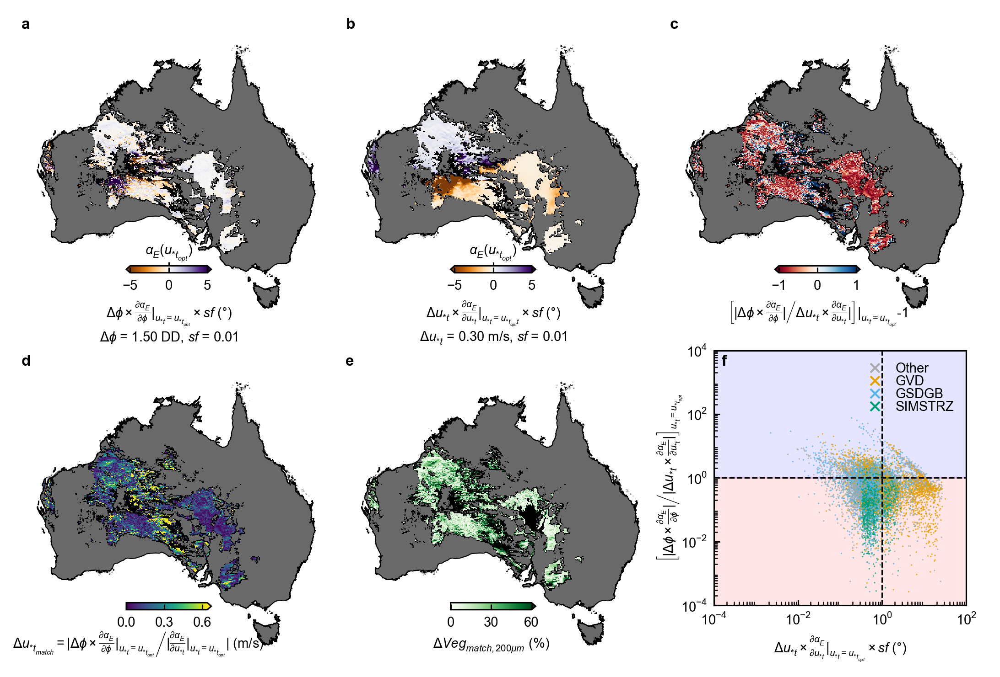

In [60]:
dl = 1.5 # latitude change
du = 0.3 # threshold friction velocity
sf = 0.01 # scale factor

draft = True

### Colormap for nnan data
import matplotlib as mpl
cmap = mpl.colormaps['spring']
but0c = cmap(0.0)

### Setup figure
figw,figh = 180/25.4,120/25.4 
figa = figw/figh

### Panel label setup
labc = 'lower'
labx = (fs+1)/2/72/figw
laby = labx*figa*(2+(0 if labc=='lower' else 0.5))
labs = ['a','b','c','d','e','f','g','h','i'] 

### Scatter plot labels
labels = ['No match','Other','GVD','GSDGB','SIMSTRZ']
colors = ['black',"darkgrey","#E69F00","#56B4E9","#009E73"]
cmap = ListedColormap(colors[1:])

### Buffer definitions (could do with a clean up)
xoffl=0.05771995659722229
xoffr=0.011465277777777727
yoffb=0.06155972222222222
yofft=0.0077611111111111075
bufx = 0.01
bufy = bufx*figa

### Axis definitons (could do with a cleanup)
ax0w = (1-2*xoffr-2*bufx)/3
ax0h = ax0w*figa
ax0l,ax0b = xoffr,1-fs/2/72-ax0h
ax1l,ax1b,ax1w,ax1h = ax0l+ax0w+bufx,ax0b,ax0w,ax0h
ax2l,ax2b,ax2w,ax2h = 2/3+xoffl+0.00035277777777786845-0.005038475115740848,yoffb,1/3-xoffl-xoffr+0.005038475115740848,0.5-yoffb
ax3l,ax3b,ax3w,ax3h = xoffr,yoffb,ax0w,ax0h
testoff=1-(2/3+xoffl+0.00035277777777786845-0.005038475115740848+1/3-xoffl-xoffr+0.005038475115740848)+0.01

### PLOTTING ###
fig = plt.figure(figsize=(figw,figh)) 

### Top left panel: elongationmode sensitivity to change in latitude
ax = fig.add_axes([testoff,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r")
pcm = ax.pcolormesh(ds.longitude,ds.latitude,(ds.daedphi_opt*dl*sf*180/np.pi).where(~np.isnan(ds.ut_opt)),vmin=-5,vmax=5,cmap="PuOr")
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
cax.set_xlabel("$\\Delta \\phi \\times \\frac{\\partial \\alpha_{E}}{\\partial \\phi}|_{u_{*t}=u_{*t_{opt}}} \\times sf$ (°)\n$\\Delta \\phi$ = %.2f DD, $sf$ = %.2f"%(dl,sf))
cax.set_xticks([-5,0,5])
cax.text(0, 1.4, '$\\alpha_E(u_{*t_{opt}})$',color='k',ha='center', va='bottom',transform=cax.get_xaxis_transform())
cax.axvline(x=0, color='k', linewidth=0.75, ymin=1.1, ymax=1.4,clip_on=False)
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Top middle panel: elongationmode sensitivity to change in ut
ax = fig.add_axes([testoff+1/3,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r")
pcm = ax.pcolormesh(ds.longitude,ds.latitude,(ds.daedut_opt*du*sf*180/np.pi).where(~np.isnan(ds.ut_opt)),vmin=-5,vmax=5,cmap="PuOr")
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
cax.set_xlabel("$\\Delta u_{*t} \\times \\frac{\\partial \\alpha_{E}}{\\partial u_{*t}}|_{u_{*t}=u_{*t_{opt}t}} \\times sf$ (°)\n$\\Delta u_{*t}$ = %.2f m/s, $sf$ = %.2f"%(du,sf))
cax.set_xticks([-5,0,5])
cax.text(0, 1.4, '$\\alpha_E(u_{*t_{opt}})$',color='k',ha='center', va='bottom',transform=cax.get_xaxis_transform())
cax.axvline(x=0, color='k', linewidth=0.75, ymin=1.1, ymax=1.4,clip_on=False)
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Top right: Ratio of changes in top left and top middle panel
ax = fig.add_axes([testoff+2/3,0+0.0038805555555555538+0.5,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r")
pcm = ax.pcolormesh(ds.longitude,ds.latitude,(abs(ds.daedphi_opt*dl*sf*180/np.pi)/abs(ds.daedut_opt*du*sf*180/np.pi)-1).where(~np.isnan(ds.ut_opt)),vmin=-1,vmax=1,cmap="RdBu")
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="both")
# cax.set_xlabel(
#     r"$\left[\frac{|\Delta\phi\times\frac{\partial \alpha_E}{\partial \phi}|}"
#     r"{|\Delta u_{*t}\times\frac{\partial \alpha_E}{\partial u_{*t}}|}\right]|"
#     r"_{u_{*t}=u_{*opt}}$-1"
# )
cax.set_xlabel(
    r"$\left[|\Delta\phi\times\frac{\partial \alpha_E}{\partial \phi}|"
    r"\middle/\Delta u_{*t}\times\frac{\partial \alpha_E}{\partial u_{*t}}|\right]|"
    r"_{u_{*t}=u_{*t_{opt}}}$-1"
)
cax.set_xticks([-1,0,1])
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Bottom left: Change in ut required to match the influence of 1.5 DD change in latitude
du_comp = (abs(ds.daedphi_opt)*dl/abs(ds.daedut_opt)) # change in ut required to match change in latitude position
ax = fig.add_axes([testoff,0+0.0038805555555555538 -0.02,1/3-2*testoff,1/2-yofft])
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r")
pcm = ax.pcolormesh(ds.longitude,ds.latitude,du_comp.where(~np.isnan(ds.ut_opt)),vmin=0,vmax=0.64,cmap="viridis")
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="max")
# cax.set_xlabel("$\\Delta u_{*t_{match}} = \\frac{|\\Delta \\phi \\times \\frac{\\partial \\alpha_{E}}{\\partial \\phi}|_{u_{*t}=u_{*opt}}|}{|\\frac{\\partial \\alpha_{E}}{\\partial u_{*t}}|_{u_{*t}=u_{*opt}}|}$ (m/s)",labelpad=0)
# cax.set_xticks([0,0.3,0.6])
cax.set_xlabel(r"$\Delta u_{*t_{match}} = \left.|\Delta \phi \times \frac{\partial \alpha_{E}}{\partial \phi}|_{u_{*t}=u_{*t_{opt}}}\middle/|\frac{\partial \alpha_{E}}{\partial u_{*t}}|_{u_{*t}=u_{*t_{opt}}}|\right.$ (m/s)",labelpad=0,loc="right")
cax.set_xticks([0,0.3,0.6])
cax.xaxis.set_label_coords(1.7,-3)
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Bottom middle: Approximate equivalent of change in vegetation to bottom left panel
# evaluating the change in veg if we where to increase the baseline (utopt) by the amount of ut match
Av_base = Av_from_ut(ds.ut_opt, 200e-6)
Av_new  = Av_from_ut(ds.ut_opt + du_comp, 200e-6)
dAv_comp = Av_new - Av_base
ax = fig.add_axes([testoff+1/3,0+0.0038805555555555538-0.02,1/3-2*testoff,1/2-yofft]) 
ax.pcolormesh(ds.longitude,ds.latitude, ds.dune_mask.where(ds.dune_mask), cmap="Greys_r")
pcm = ax.pcolormesh(ds.longitude,ds.latitude,np.where(~np.isnan(ds.ut_opt),dAv_comp*100,np.nan),vmin=0,vmax=60,cmap="Greens")
cax = ax.inset_axes([0.325,0.15,0.3,0.025], transform=ax.transAxes)
cbar = plt.colorbar(pcm, cax=cax, orientation='horizontal', shrink=.05,extend="max")
cax.set_xlabel("$\\Delta Veg{_{match,200\\mu m}}$ (%)")
cax.set_xticks([0,30,60])
AUS_back(ax)
ax.set_xlim(112.5,154)
ax.set_ylim(-44.5,-8)
ax.axis("off")

### Bottom right: Relative sensitivity of top left panel and top middle panel over top middle scatter
ax = fig.add_axes([ax2l,ax2b+0.045-0.02,ax2w-0.01,ax2h-0.045])
ax.fill_between([10**-4,10**2],1,0,color="red",zorder=0,alpha=0.1)
ax.fill_between([10**-4,10**2],1,10**4,color="blue",zorder=0,alpha=0.1)
regmask = ((~np.isnan(ds.ut_opt)&ds.GVD)*2+(~np.isnan(ds.ut_opt)&ds.GSDGB)*3+(~np.isnan(ds.ut_opt)&ds.SIMSTRZ)*4)
regmask = xr.where((~np.isnan(ds.ut_opt)&(regmask==0)),1,regmask)
regscat = pd.concat([np.abs(ds.daedut_opt*du*sf*180/np.pi).to_dataframe("dzdu"),(np.abs(ds.daedphi_opt*dl*sf*180/np.pi)/np.abs(ds.daedut_opt*du*sf*180/np.pi)).to_dataframe("dzdl_dzdu"),regmask.to_dataframe("region")],axis=1).dropna().sample(frac=1,random_state=10)
regscat["region_color"] = [colors[i] for i in regscat.region]
ax.scatter(regscat.dzdu,regscat.dzdl_dzdu,c=regscat.region_color,marker="x",s=0.1,alpha=0.75)
handles = [Line2D([0],[0],marker='x',color='none',markeredgecolor=colors[1:][i],markersize=1,label=labels[1:][i]) for i in range(len(labels[1:]))]
ax.legend(handles=handles,markerscale=5,frameon=False,loc=1,labelspacing=0)
ax.set_xlabel("$\\Delta u_{*t} \\times \\frac{\\partial \\alpha_{E}}{\\partial u_{*t}}|_{u_{*t}=u_{*t_{opt}}} \\times sf$ (°)")
# ax.set_ylabel(r"$\left[|\Delta\phi\times\frac{\partial \alpha_E}{\partial \phi}|"
#     r"/|\Delta u_{*t}\times\frac{\partial \alpha_E}{\partial u_{*t}}|\right]|"
#     r"_{u_{*t}=u_{*opt}}$",va="baseline")
ax.set_ylabel(
    r"$\left[|\Delta\phi\times\frac{\partial \alpha_E}{\partial \phi}|"
    r"\middle/|\Delta u_{*t}\times\frac{\partial \alpha_E}{\partial u_{*t}}|\right]"
    r"_{u_{*t}=u_{*t_{opt}}}$",
    va="baseline"
)
ax.axhline(1,color="k",ls="dashed")
ax.axvline(1,color="k",ls="dashed")
plt.xscale("log")
plt.yscale("log")
ax.set_xlim(10**-4,10**2)
ax.set_ylim(10**-4,10**4)
ax.set_xticks([10**-4,10**-2,1,10**2])
ax.set_yticks([10**-4,10**-2,1,10**2,10**4])

### Draft axis and panel labels
ax = fig.add_axes([0,0,1,1]) 
ax.text(0+labx,1-laby,labs[0],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(1/3+labx,1-laby,labs[1],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(2/3+labx,1-laby,labs[2],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(0+labx,1/2-laby-0.02,labs[3],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(1/3+labx,1/2-laby-0.02,labs[4],ha='left',va='baseline',fontsize=fs+1,fontweight='bold')
ax.text(2/3+xoffl+0.00035277777777786845-0.005038475115740848+labx,1/2-laby-0.02,labs[5],ha='left',va='baseline',fontsize=fs+1,fontweight='bold') # inside the scatter plot
ax.patch.set_alpha(0)
plt.xticks([])
plt.yticks([])

if not draft:
    ax.axis('off') 
    fig.savefig('paper_ready_plots/Extended_5_dlat_dut_opt.png')

##### For fixed dm